In [1]:
# code from https://satijalab.org/seurat/articles/integration_mapping#unimodal-umap-projection

# setwd("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/data") # change to local tutorial directory
setwd("/hpcwork/p0020567/data/dbit-seq/spatial_atac/archr/combined_4_1000/")

rm(list = ls())
library(ArchR)
library(Seurat)
library(grid)
#library("glmGamPoi")
library(dplyr)
set.seed(1234)


threads = 10
addArchRThreads(threads = threads)
addArchRGenome("hg38")


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
           ___      .______        ______  __    __  .______      
          /   \     |   _ 

In [2]:
source("/work/p0020567/kaili_projects/dbit-seq/scripts/utils/getGeneScore_ArchR.R")

In [3]:
packageVersion("Seurat")

[1] ‘5.3.0’

### Read in the annotated ArchR project which has been integrated with scRNA data

In [4]:
print(Sys.time())
#proj <- readRDS("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/data/processed/scATAC/r_objects/kidney7_integrate_scRNA_res2.5_annotation.rds")
#proj <- loadArchRProject("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/results/analysis/ATAC/figures/pdf/20mm/ArchR/with_peak_ref/")
proj <- readRDS("kidney7_marker_peak_integrate_scATAC_res0.9_annoted2.rds")

[1] "2026-06-10 17:02:40 CEST"


### Visualize annotation on UMAP clusters

In [5]:
head(as.data.frame(proj@cellColData))

,Sample,TSSEnrichment,ReadsInTSS,ReadsInPromoter,ReadsInBlacklist,PromoterRatio,PassQC,NucleosomeRatio,nMultiFrags,nMonoFrags,nFrags,nDiFrags,BlacklistRatio,Clusters,Clusters2,ReadsInPeaks,FRIP
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>
63079#GACAGTGCACCACTGT-1,63079,6.205,32938,41744,2201,0.12371965,1,0.3950550,13700,120930,168704,34074,0.006523260,C1,Unannotated,42001,0.12448134
63079#GAGTTAGCACATTGGC-1,63079,6.162,24582,31475,1816,0.11975786,1,0.4410681,11399,91190,131411,28822,0.006909619,C1,Unannotated,30256,0.11511974
63079#GAACAGGCACAAGCTA-1,63079,5.070,16319,21443,1703,0.08561037,1,0.4958375,11992,83723,125236,29521,0.006799163,C7,CD,21941,0.08759861
63079#GACAGTGCACAAGCTA-1,63079,5.799,18521,24065,1885,0.09757848,1,0.5238631,12022,80920,123311,30369,0.007643276,C7,CD,22246,0.09020282
63079#CCTCTATCAAGACGGA-1,63079,5.186,13849,18582,1942,0.07921391,1,0.4811214,11082,79190,117290,27018,0.008278626,C1,Unannotated,19489,0.08308040
63079#GATGAATCCAGATCTG-1,63079,6.900,20040,24947,1293,0.13614088,1,0.4377942,7799,63724,91622,20099,0.007056166,C11,VSMC/Pericytes,20939,0.11426841


ArchR logging to : ArchRLogs/ArchR-plotEmbedding-3a431be96f77-Date-2026-06-10_Time-17-02-46.087133.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = cellColData

Plotting Embedding

1 
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the ArchR package.
  Please report the issue to the authors.”
Warning message:
“The `size` argument of `element_rect()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the ArchR package.
  Please report the issue to the authors.”
Warning message:
“`aes_()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`
ℹ The deprecated feature was likely used in the ArchR package.
  Please report the issue to the authors.”


ArchR logging successful to : ArchRLogs/ArchR-plotEmbeddi

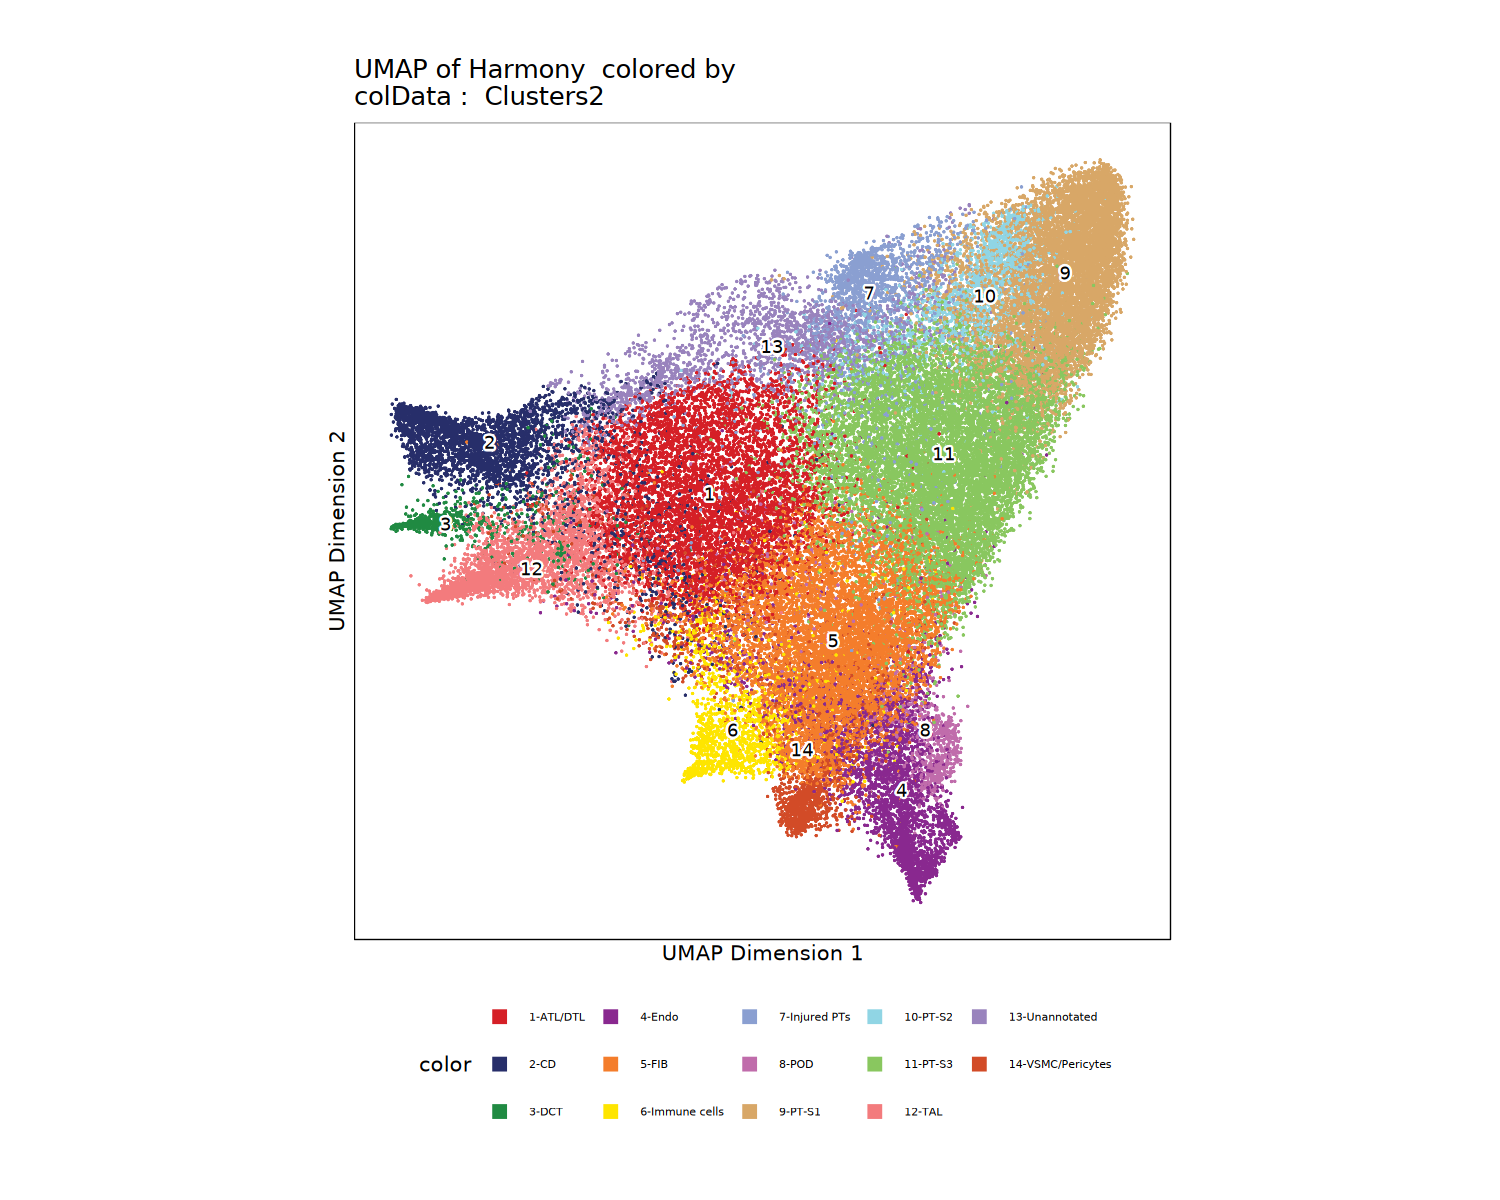

In [6]:
options(repr.plot.width=10, repr.plot.height=8, repr.plot.res = 150)
plotEmbedding(ArchRProj = proj, colorBy = "cellColData", name = "Clusters2", embedding = "UMAP")

In [7]:
proj <- addImputeWeights(proj)

ArchR logging to : ArchRLogs/ArchR-addImputeWeights-3a431733bd2ca-Date-2026-06-10_Time-17-03-00.096346.log
If there is an issue, please report to github with logFile!

2026-06-10 17:03:00.216465 : Computing Impute Weights Using Magic (Cell 2018), 0 mins elapsed.

Filtering 1 dims correlated > 0.75 to log10(depth + 1)



### Read in the scRNA data

In [8]:
print(Sys.time())
#muto_data <- readRDS("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/scRNA/scrna_phase_clustering.rds")
muto_data <- readRDS("/hpcwork/p0020567/data/dbit-seq/scRNA_data/scrna_seurat_pipeline_results_2/kidney7/save/scrna_phase_clustering.rds")

[1] "2026-06-09 10:43:11 CEST"


In [9]:
head(muto_data@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,name,stage,percent.mt,percent.ribo,nCount_decontX,nFeature_decontX,AmbientRNA,⋯,RNA_snn_res.0.8,integrated_snn_res.1.5,seurat_inte_clusters,RNA_snn_res.1.5,harmony_inte_clusters,MCA_annotate,external_annotation,HCL_annotate,res1.5.annotation,res0.4.annotation
,<chr>,<dbl>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<chr>,<chr>,<chr>,<fct>,<fct>
hk_63079_AAACAAGCAATGAGCCACTTTAGG-1,Human Kidney project,1170,898,hk_63079,control,0.08547009,0,1100.031,898,0.05984452,⋯,15,24,24,19,19,NA,Podocytes,Endothelial.cell.Adult.Kidney,Descending Vasa Recta Endothelial,Peritubular Capilary Endothelial
hk_63079_AAACAAGCACCAGCTCACTTTAGG-1,Human Kidney project,1040,777,hk_63079,control,0.00000000,0,1012.354,777,0.02673831,⋯,0,1,1,6,6,NA,Mesangial cells,Smooth.muscle.cell.Adult.Kidney,Fibroblast2,Fibroblast
hk_63079_AAACAAGCACGAACGTACTTTAGG-1,Human Kidney project,3387,2048,hk_63079,control,2.09625037,0,3302.690,2048,0.02491182,⋯,4,10,10,2,2,NA,Proximal tubule cells,Proximal.tubule.cell.Adult.Kidney,Proximal Tubule Epithelial Segment1,Proximal Tubule Epithelial
hk_63079_AAACAAGCATTCATGCACTTTAGG-1,Human Kidney project,1045,697,hk_63079,control,0.09569378,0,1024.754,697,0.01939621,⋯,0,3,3,4,4,Macrophage_Lyz2 high(Kidney),Smooth muscle,Smooth.muscle.cell.Adult.Kidney,Fibroblast1,Fibroblast
hk_63079_AAACCAATCAGGGCACACTTTAGG-1,Human Kidney project,1076,801,hk_63079,control,0.18587361,0,1001.867,801,0.06899314,⋯,0,1,1,6,6,NA,Podocytes,Smooth.muscle.cell.Adult.Kidney,Fibroblast2,Fibroblast
hk_63079_AAACCAATCATAATGGACTTTAGG-1,Human Kidney project,1164,805,hk_63079,control,0.51546392,0,1120.205,805,0.03784387,⋯,0,3,3,4,4,NA,Mesangial cells,Fibroblast.Adult.Kidney,Fibroblast1,Fibroblast


#### UMAP for the scRNA-seq data

In [10]:
muto_data

An object of class Seurat 
51374 features across 57679 samples within 4 assays 
Active assay: RNA (16458 features, 2000 variable features)
 3 other assays present: decontX, integrated, MAGIC_RNA
 9 dimensional reductions calculated: RAW_PCA, BCELLCYCLE_PCA, CELLCYCLED_PCA, RegressOut_PCA, harmony, harmony_UMAP, INTE_PCA, INTE_UMAP, DEFAULT_UMAP

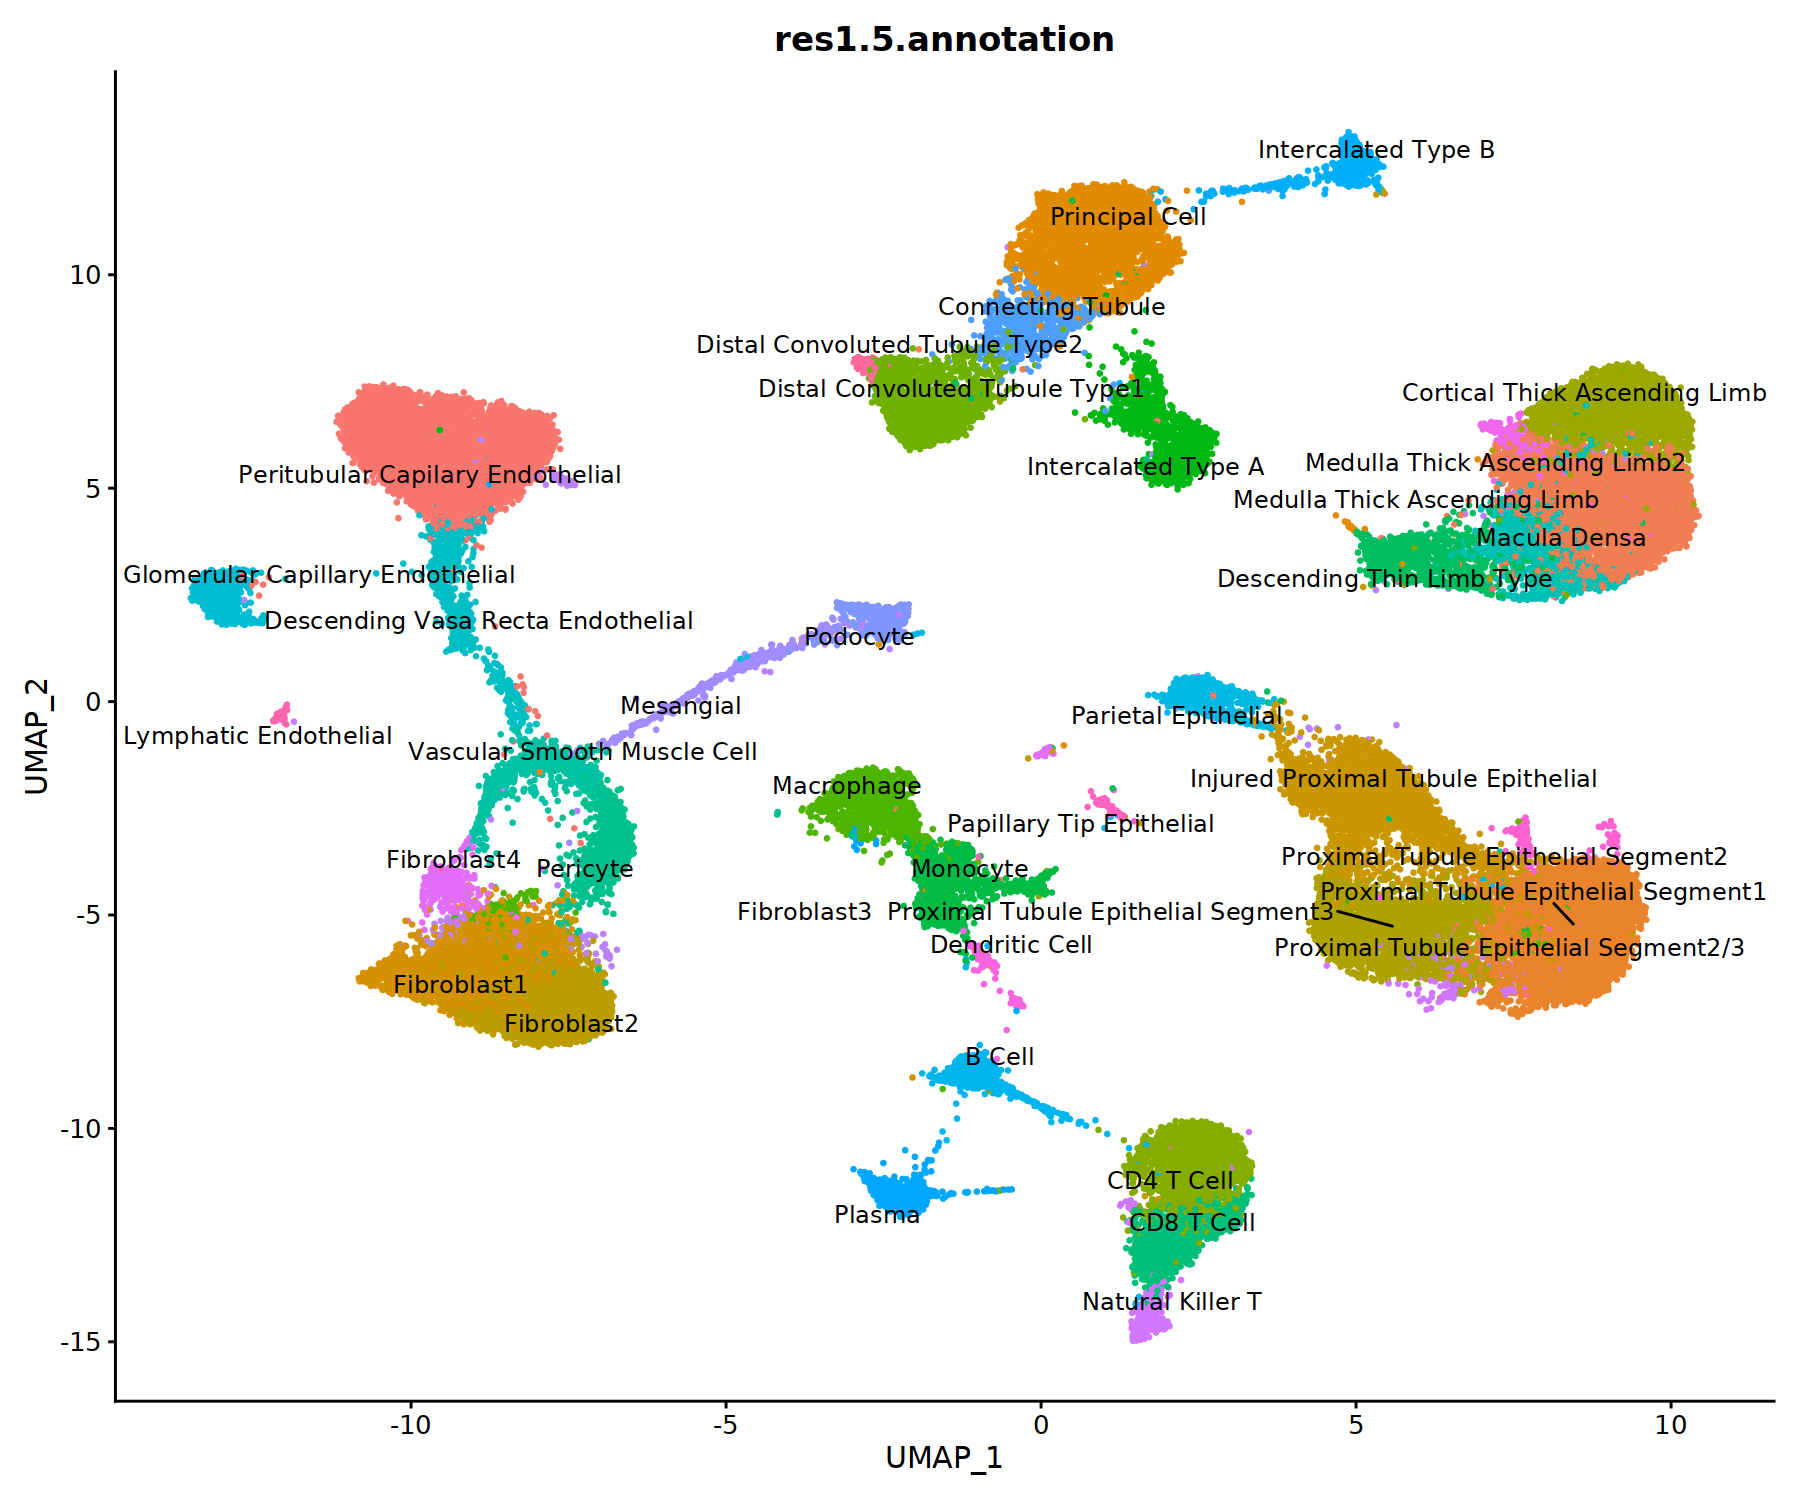

In [11]:
options(repr.plot.width=12, repr.plot.height=10, repr.plot.res = 150)
DimPlot(object = muto_data, group.by = "res1.5.annotation", pt.size = 0.5, raster=FALSE, label = TRUE, repel = TRUE) + NoLegend()

#### Merge several clusters

In [12]:
unique(as.vector(muto_data@meta.data$res1.5.annotation))

[1] "Descending Vasa Recta Endothelial"    
 [2] "Fibroblast2"                          
 [3] "Proximal Tubule Epithelial Segment1"  
 [4] "Fibroblast1"                          
 [5] "Peritubular Capilary Endothelial"     
 [6] "Medulla Thick Ascending Limb"         
 [7] "Parietal Epithelial"                  
 [8] "Cortical Thick Ascending Limb"        
 [9] "Principal Cell"                       
[10] "Connecting Tubule"                    
[11] "Injured Proximal Tubule Epithelial"   
[12] "Descending Thin Limb Type"            
[13] "Fibroblast3"                          
[14] "Proximal Tubule Epithelial Segment3"  
[15] "Intercalated Type A"                  
[16] "Distal Convoluted Tubule Type1"       
[17] "Pericyte"                             
[18] "Podocyte"                             
[19] "Mesangial"                            
[20] "Distal Convoluted Tubule Type2"       
[21] "Glomerular Capillary Endothelial"     
[22] "Vascular Smooth Muscle Cell"          
[23] "Medulla Thick Ascending Limb2"        
[24] "Macrophage"                           
[25] "Intercalated Type B"                  
[26] "Fibroblast4"                          
[27] "Macula Densa"                         
[28] "Monocyte"                             
[29] "CD4 T Cell"                           
[30] "Natural Killer T"                     
[31] "Papillary Tip Epithelial"             
[32] "CD8 T Cell"                           
[33] "Plasma"                               
[34] "Proximal Tubule Epithelial Segment2"  
[35] "Lymphatic Endothelial"                
[36] "B Cell"                               
[37] "Dendritic Cell"                       
[38] "Proximal Tubule Epithelial Segment2/3"

In [13]:
library(dplyr)

muto_data@meta.data <- muto_data@meta.data %>%
  mutate(
    Annotation = case_when(
      
      # ---- fibroblast 合并 ----
      res1.5.annotation %in% c("Fibroblast1", "Fibroblast2", "Fibroblast3", "Fibroblast4") ~ "Fibroblast",
      
      # ---- DCT 合并 ----
      res1.5.annotation %in% c("Distal Convoluted Tubule Type1", "Distal Convoluted Tubule Type2") ~ "Distal Convoluted Tubule",
      
      # ---- TAL 合并 ----
      res1.5.annotation %in% c("Medulla Thick Ascending Limb", "Medulla Thick Ascending Limb2") ~ "Medulla Thick Ascending Limb",
      
      # ---- PT Segment 合并 ----
      res1.5.annotation %in% c(
        "Proximal Tubule Epithelial Segment2/3",
        "Proximal Tubule Epithelial Segment3"
      ) ~ "Proximal Tubule Epithelial Segment3",
      
      # ---- 其他保持不变 ----
      TRUE ~ as.character(res1.5.annotation)
    )
  )

In [14]:
head(muto_data@meta.data[,c("name", "res1.5.annotation", "Annotation")])

,name,res1.5.annotation,Annotation
,<chr>,<fct>,<chr>
hk_63079_AAACAAGCAATGAGCCACTTTAGG-1,hk_63079,Descending Vasa Recta Endothelial,Descending Vasa Recta Endothelial
hk_63079_AAACAAGCACCAGCTCACTTTAGG-1,hk_63079,Fibroblast2,Fibroblast
hk_63079_AAACAAGCACGAACGTACTTTAGG-1,hk_63079,Proximal Tubule Epithelial Segment1,Proximal Tubule Epithelial Segment1
hk_63079_AAACAAGCATTCATGCACTTTAGG-1,hk_63079,Fibroblast1,Fibroblast
hk_63079_AAACCAATCAGGGCACACTTTAGG-1,hk_63079,Fibroblast2,Fibroblast
hk_63079_AAACCAATCATAATGGACTTTAGG-1,hk_63079,Fibroblast1,Fibroblast


In [15]:
print(Sys.time())
saveRDS(muto_data, "/hpcwork/p0020567/data/dbit-seq/scRNA_data/scrna_seurat_pipeline_results_2/kidney7/save/scrna_phase_clustering_rename.rds")

[1] "2026-06-09 10:46:13 CEST"


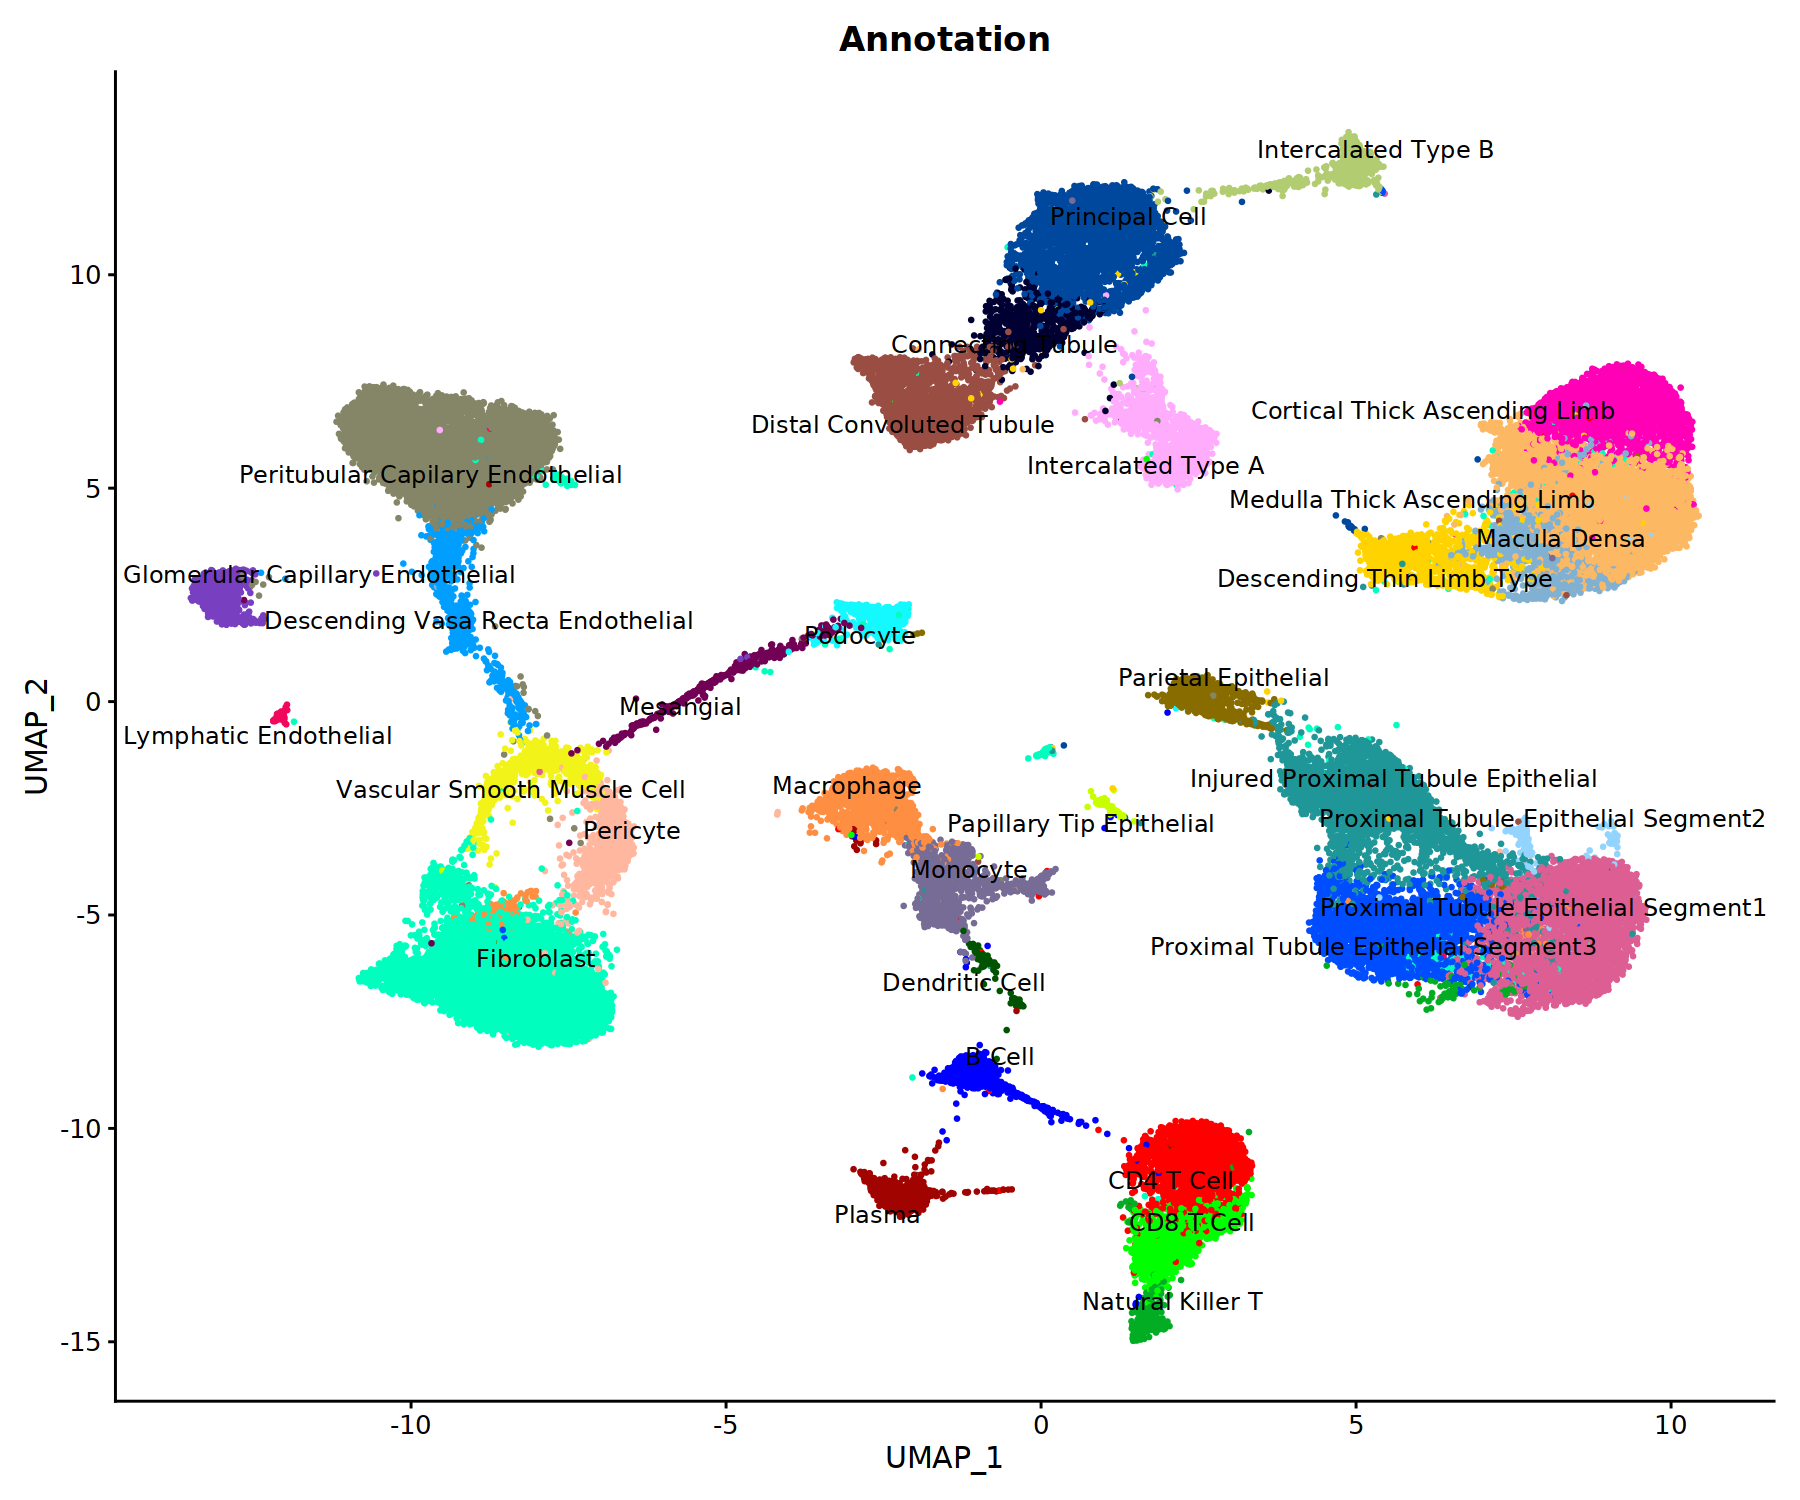

In [16]:
anno_levels <- levels(factor(muto_data$Annotation))

cols <- Seurat:::DiscretePalette(length(anno_levels))
names(cols) <- anno_levels

cols["Medulla Thick Ascending Limb"] <- "#FDB863"  # 浅橙
cols["Macula Densa"] <- "#80B1D3" 

options(repr.plot.width=12, repr.plot.height=10, repr.plot.res = 150)
DimPlot(object = muto_data, group.by = "Annotation", pt.size = 0.5, raster=FALSE, label = TRUE, repel = TRUE, cols = cols) + NoLegend()

#### Save pdf for the sinlge cell reference data

In [17]:
pdf("/hpcwork/p0020567/data/dbit-seq/spatial_atac/archr/combined_4_1000/scrna_phase_clustering_res_1.5.pdf", width = 12, height = 10)
DimPlot(object = muto_data, group.by = "res1.5.annotation", pt.size = 0.8, raster=FALSE, label = TRUE) + NoLegend()
dev.off()

png 
  2

### Read in the saved scRNA-seq data

In [8]:
print(Sys.time())
muto_data <- readRDS("/hpcwork/p0020567/data/dbit-seq/scRNA_data/scrna_seurat_pipeline_results_2/kidney7/save/scrna_phase_clustering_rename.rds")

[1] "2026-06-10 17:03:51 CEST"


In [9]:
muto_data

An object of class Seurat 
51374 features across 57679 samples within 4 assays 
Active assay: RNA (16458 features, 2000 variable features)
 3 layers present: counts, data, scale.data
 3 other assays present: decontX, integrated, MAGIC_RNA
 9 dimensional reductions calculated: RAW_PCA, BCELLCYCLE_PCA, CELLCYCLED_PCA, RegressOut_PCA, harmony, harmony_UMAP, INTE_PCA, INTE_UMAP, DEFAULT_UMAP

#### Rerun UMAP for reference RNA-seq data

In [10]:
ref <- muto_data

In [11]:
for (red in Reductions(ref)) {
  cat("Checking:", red, "\n")
  tryCatch({
    validObject(ref[[red]])
    cat("  OK\n\n")
  }, error = function(e) {
    cat("  ❌ BROKEN:", e$message, "\n\n")
  })
}

Checking: RAW_PCA 
  OK

Checking: BCELLCYCLE_PCA 
  ❌ BROKEN: invalid class “DimReduc” object: Keys must match the pattern ‘^[a-zA-Z][a-zA-Z0-9]*_$’ 

Checking: CELLCYCLED_PCA 
  ❌ BROKEN: invalid class “DimReduc” object: Keys must match the pattern ‘^[a-zA-Z][a-zA-Z0-9]*_$’ 

Checking: RegressOut_PCA 
  ❌ BROKEN: invalid class “DimReduc” object: Keys must match the pattern ‘^[a-zA-Z][a-zA-Z0-9]*_$’ 

Checking: harmony 
  OK

Checking: harmony_UMAP 
  OK

Checking: INTE_PCA 
  ❌ BROKEN: invalid class “DimReduc” object: Keys must match the pattern ‘^[a-zA-Z][a-zA-Z0-9]*_$’ 

Checking: INTE_UMAP 
  ❌ BROKEN: invalid class “DimReduc” object: Keys must match the pattern ‘^[a-zA-Z][a-zA-Z0-9]*_$’ 

Checking: DEFAULT_UMAP 
  ❌ BROKEN: invalid class “DimReduc” object: Keys must match the pattern ‘^[a-zA-Z][a-zA-Z0-9]*_$’ 



In [12]:
DefaultDimReduc(ref)

[1] "harmony_UMAP"

In [13]:
Reductions(ref)

[1] "RAW_PCA"        "BCELLCYCLE_PCA" "CELLCYCLED_PCA" "RegressOut_PCA"
[5] "harmony"        "harmony_UMAP"   "INTE_PCA"       "INTE_UMAP"     
[9] "DEFAULT_UMAP"

In [14]:
genes.use <- VariableFeatures(ref)

In [15]:
genes.use

[1] "REN"        "IGHA1"      "JCHAIN"     "IGHG1"      "LTF"       
   [6] "NPHS2"      "NDNF"       "LYZ"        "PTPRO"      "IGKC"      
  [11] "SELE"       "IGHM"       "KLK1"       "SOD3"       "PODXL"     
  [16] "HTRA1"      "CHI3L1"     "NPHS1"      "MYH11"      "IGHG3"     
  [21] "GNLY"       "FCER1A"     "CCL19"      "CLIC5"      "MMP7"      
  [26] "SPOCK1"     "IRF8"       "C3"         "PCOLCE2"    "CCL4"      
  [31] "ICAM1"      "CCL8"       "SLC26A4"    "SLPI"       "RGS5"      
  [36] "IGFBP6"     "DDN"        "SLC4A9"     "PLA2R1"     "SERPINE1"  
  [41] "IGLC1"      "S100A9"     "NRXN1"      "SLC4A1"     "CXCL10"    
  [46] "STC1"       "COMP"       "PTGDS"      "C1QA"       "KRT17"     
  [51] "PAPPA2"     "MPEG1"      "RBP4"       "PTP4A3"     "KRT13"     
  [56] "C1QC"       "APOD"       "IDO1"       "SPOCK2"     "PTGS2"     
  [61] "S100A2"     "DHRS2"      "C1QB"       "CLEC10A"    "XCR1"      
  [66] "FGF1"       "FBLN1"      "CSF1R"      "WDFY4"      "AQP6"      
  [71] "RNASE1"     "DMRT2"      "FOSB"       "CCL14"      "NKG7"      
  [76] "VWF"        "MZB1"       "NPNT"       "HDC"        "SYT8"      
  [81] "TPPP3"      "ADCYAP1"    "IL6"        "CCL2"       "MAFB"      
  [86] "RGS16"      "CCL4L2"     "CCL3"       "CYP24A1"    "CD14"      
  [91] "CTSG"       "OLR1"       "DES"        "CXCL8"      "CDKN1C"    
  [96] "CRHBP"      "LIF"        "CLDN5"      "SEMA3G"     "LY6D"      
 [101] "TYRO3"      "STAB1"      "RGS1"       "MS4A6A"     "CPA3"      
 [106] "NR4A3"      "WT1"        "HIST1H1B"   "OLFM4"      "CRB2"      
 [111] "FN1"        "EHD3"       "PRF1"       "IGHD"       "SST"       
 [116] "IL1RL1"     "IL1B"       "CCL20"      "S100A8"     "MUC6"      
 [121] "CCL21"      "CALB1"      "CLDN11"     "CXCL1"      "CD83"      
 [126] "TNC"        "SPRY1"      "S100P"      "PLAT"       "EGR3"      
 [131] "TRBC2"      "RIPPLY1"    "CSF2RA"     "MCAM"       "REG1A"     
 [136] "CXCL6"      "MT1G"       "FOXI1"      "FXYD4"      "KISS1"     
 [141] "FBLN2"      "CD36"       "COL3A1"     "TAC1"       "CD163"     
 [146] "ATP6V1C2"   "CRIP1"      "CPA4"       "PTPRQ"      "RHCG"      
 [151] "DUSP2"      "SLC8A1"     "ABCC8"      "IGFBP3"     "ACKR1"     
 [156] "F3"         "EMCN"       "MEST"       "FOLR2"      "FGB"       
 [161] "IGFBP2"     "ALS2CL"     "CHGB"       "SLC4A11"    "ATP12A"    
 [166] "SFRP4"      "MS4A7"      "COL1A1"     "NTNG1"      "IGFBP1"    
 [171] "PSCA"       "CD1C"       "AIF1"       "LUM"        "SPINK1"    
 [176] "KLK6"       "MARCOL"     "ELN"        "ITGB6"      "VCAN"      
 [181] "HYAL2"      "ACTA2"      "LTB"        "DEPP1"      "NR4A2"     
 [186] "ITGAX"      "AGR2"       "TMPRSS4"    "FSTL3"      "SLC26A7"   
 [191] "LCN2"       "TRAC"       "LAMC3"      "TNFSF18"    "DERL3"     
 [196] "COL6A3"     "SOST"       "SSUH2"      "CLNK"       "OLFM3"     
 [201] "LAMP5"      "MME"        "MGP"        "CSPG4"      "CYBB"      
 [206] "TXNDC5"     "CNN1"       "CLEC9A"     "C11orf96"   "CLDN4"     
 [211] "ATF3"       "MUC3A"      "INHBA"      "CLDN2"      "RERGL"     
 [216] "CD209"      "EGR2"       "TRBC1"      "DCN"        "F13A1"     
 [221] "SLC12A3"    "KRT7"       "LYVE1"      "ANKRD1"     "MRC1"      
 [226] "PI16"       "EDN2"       "FCGR3A"     "VNN1"       "CD207"     
 [231] "MMP9"       "RAB7B"      "JAML"       "TACSTD2"    "MFAP4"     
 [236] "HBB"        "ADAMTS1"    "FGL2"       "MS4A2"      "SLC34A2"   
 [241] "THBD"       "TCF21"      "LAPTM5"     "WFDC2"      "PLK2"      
 [246] "VCAM1"      "SPI1"       "AQP2"       "HMGCS2"     "MS4A1"     
 [251] "AQP3"       "MT1F"       "FABP1"      "RGS2"       "ENPP2"     
 [256] "COL7A1"     "NKAIN4"     "SLC7A13"    "FHL1"       "NEURL3"    
 [261] "MYBPH"      "RRAD"       "INSRR"      "CCL5"       "CHODL"     
 [266] "CXCR4"      "MMP2"       "ESM1"       "COL1A2"     "KRT5"      
 [271] "TMEM252"    "ZDHHC6"     "LILRA4"     "SCNN1G"     "SBSPON"    
 [276] "CYP3A5"     "IL7R"       "EMP1"    

In [16]:
length(genes.use)

[1] 2000

### Run the Seurat pipeline on gene score matrix of spatial-ATAC-seq data

In [17]:
genes_spATAC <- getFeatures(
  ArchRProj = proj,
  useMatrix = "GeneScoreMatrix",
  select = NULL,
  ignoreCase = TRUE
)

In [18]:
genes.use <- genes.use[which(genes.use %in% genes_spATAC)]

In [19]:
imputation <- getGeneScore_ArchR(ArchRProj = proj, name = genes.use, imputeWeights = getImputeWeights(proj)) #name = gsub("\\-", "_", genes.use)
imputation <- log(imputation + 1)

Getting ImputeWeights

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-3a4314484f008-Date-2026-06-10_Time-17-06-21.039097.log
If there is an issue, please report to github with logFile!

Getting Matrix Values...

2026-06-10 17:06:21.44552 : 



Imputing Matrix

Using weights on disk

Using weights on disk



ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-3a4314484f008-Date-2026-06-10_Time-17-06-21.039097.log



In [20]:
imputation[1:5, 1:5]

,63079#GACAGTGCACCACTGT-1,63079#GAGTTAGCACATTGGC-1,63079#GAACAGGCACAAGCTA-1,63079#GACAGTGCACAAGCTA-1,63079#CCTCTATCAAGACGGA-1
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
REN,0.4770048,0.4122456,0.3911911,0.4261740,0.4078193
JCHAIN,0.1271590,0.1147204,0.1300678,0.1201417,0.1227667
LTF,0.2957363,0.3227683,0.2780552,0.2927412,0.3043426
NPHS2,0.1288375,0.1116734,0.1200642,0.1240424,0.1090358
NDNF,0.1942259,0.1778427,0.1579480,0.2070297,0.1778882


In [21]:
metadata_spatac <- as.data.frame(proj@cellColData)

In [22]:
head(metadata_spatac)

,Sample,TSSEnrichment,ReadsInTSS,ReadsInPromoter,ReadsInBlacklist,PromoterRatio,PassQC,NucleosomeRatio,nMultiFrags,nMonoFrags,nFrags,nDiFrags,BlacklistRatio,Clusters,Clusters2,ReadsInPeaks,FRIP
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>
63079#GACAGTGCACCACTGT-1,63079,6.205,32938,41744,2201,0.12371965,1,0.3950550,13700,120930,168704,34074,0.006523260,C1,Unannotated,42001,0.12448134
63079#GAGTTAGCACATTGGC-1,63079,6.162,24582,31475,1816,0.11975786,1,0.4410681,11399,91190,131411,28822,0.006909619,C1,Unannotated,30256,0.11511974
63079#GAACAGGCACAAGCTA-1,63079,5.070,16319,21443,1703,0.08561037,1,0.4958375,11992,83723,125236,29521,0.006799163,C7,CD,21941,0.08759861
63079#GACAGTGCACAAGCTA-1,63079,5.799,18521,24065,1885,0.09757848,1,0.5238631,12022,80920,123311,30369,0.007643276,C7,CD,22246,0.09020282
63079#CCTCTATCAAGACGGA-1,63079,5.186,13849,18582,1942,0.07921391,1,0.4811214,11082,79190,117290,27018,0.008278626,C1,Unannotated,19489,0.08308040
63079#GATGAATCCAGATCTG-1,63079,6.900,20040,24947,1293,0.13614088,1,0.4377942,7799,63724,91622,20099,0.007056166,C11,VSMC/Pericytes,20939,0.11426841


In [23]:
object_spATAC <- CreateSeuratObject(counts = imputation, assay = 'GeneScore', project = 'spATAC', meta.data = as.data.frame(metadata_spatac))
DefaultAssay(object_spATAC) <- "GeneScore"

Warning message:
“Data is of class data.frame. Coercing to dgCMatrix.”


In [24]:
object_spATAC <- Seurat::ScaleData(object_spATAC, layer = "counts")

Centering and scaling data matrix



In [25]:
head(object_spATAC@meta.data)

,orig.ident,nCount_GeneScore,nFeature_GeneScore,Sample,TSSEnrichment,ReadsInTSS,ReadsInPromoter,ReadsInBlacklist,PromoterRatio,PassQC,NucleosomeRatio,nMultiFrags,nMonoFrags,nFrags,nDiFrags,BlacklistRatio,Clusters,Clusters2,ReadsInPeaks,FRIP
,<fct>,<dbl>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>
63079#GACAGTGCACCACTGT-1,spATAC,738.9492,1958,63079,6.205,32938,41744,2201,0.12371965,1,0.3950550,13700,120930,168704,34074,0.006523260,C1,Unannotated,42001,0.12448134
63079#GAGTTAGCACATTGGC-1,spATAC,732.9427,1958,63079,6.162,24582,31475,1816,0.11975786,1,0.4410681,11399,91190,131411,28822,0.006909619,C1,Unannotated,30256,0.11511974
63079#GAACAGGCACAAGCTA-1,spATAC,725.1523,1958,63079,5.070,16319,21443,1703,0.08561037,1,0.4958375,11992,83723,125236,29521,0.006799163,C7,CD,21941,0.08759861
63079#GACAGTGCACAAGCTA-1,spATAC,738.8693,1958,63079,5.799,18521,24065,1885,0.09757848,1,0.5238631,12022,80920,123311,30369,0.007643276,C7,CD,22246,0.09020282
63079#CCTCTATCAAGACGGA-1,spATAC,729.1951,1958,63079,5.186,13849,18582,1942,0.07921391,1,0.4811214,11082,79190,117290,27018,0.008278626,C1,Unannotated,19489,0.08308040
63079#GATGAATCCAGATCTG-1,spATAC,745.5329,1958,63079,6.900,20040,24947,1293,0.13614088,1,0.4377942,7799,63724,91622,20099,0.007056166,C11,VSMC/Pericytes,20939,0.11426841


In [26]:
query <- object_spATAC
query <- FindVariableFeatures(query)
query <- RunPCA(query)
query <- FindNeighbors(query, dims = 1:30)
query <- FindClusters(query)
query <- RunUMAP(query, dims = 1:30)

Finding variable features for layer counts

PC_ 1 
Positive:  CDC42EP3, TIMP2, DUSP4, ARL4C, CCDC80, AFAP1L2, NR4A2, MRC2, PALLD, EPS8L3 
	   ADGRA2, ADAM19, NAV2, MRVI1, CD44, NFATC4, KIRREL1, LSP1, ARHGDIB, SDC3 
	   AMIGO2, FBLN1, C2CD4B, FAM71A, RAPGEF5, CCR7, ITGA5, MFGE8, EGR3, COL15A1 
Negative:  GPT, SLC34A3, HNF1A, PAPLN, PDZK1, SLC6A13, PCK1, AGMAT, SMIM24, SLC5A2 
	   KCNK5, FBP1, SLC47A2, PRAP1, ERBB3, SLC22A7, SLC34A1, MT1G, CMBL, HNF4A 
	   IL17RB, MT1H, ACSF2, FUT6, SLC13A2, FAM151A, UGT1A9, G6PC, TMEM106A, AMN 
PC_ 2 
Positive:  NRG1, CCSER1, PIK3C2G, RALYL, CNTNAP5, DGKI, NRXN1, MGST1, COL22A1, RERGL 
	   CFTR, SPON1, EGLN3, SPHKAP, NELL2, KCNK2, PACRG, LMNTD1, GC, TMPRSS11E 
	   KCNH5, ENOX1, SLC34A2, DNER, SLC26A7, CD36, DIO2, TSPAN8, DKK2, TCN1 
Negative:  DDIT4, DNAJB1, CD68, IRF1, JUNB, ACAP1, KIFC1, ZFP36, HSPA1B, HSPA1A 
	   IFFO2, NR1D1, NFKBIA, BCL3, TBC1D10C, UPK2, DDIT3, HYAL2, IER5L, CRIP1 
	   RIPOR1, TUBA1B, PLK3, TEDC1, NECTIN2, PDGFB, HIST2H2BE, EMILIN1

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 55206
Number of edges: 1427780

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8553
Number of communities: 22
Elapsed time: 17 seconds


Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
17:09:10 UMAP embedding parameters a = 0.9922 b = 1.112

17:09:10 Read 55206 rows and found 30 numeric columns

17:09:10 Using Annoy for neighbor search, n_neighbors = 30

17:09:10 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

17:09:14 Writing NN index file to temp file /w0/tmp/slurm_fp015734.976678/Rtmpy4TdTc/file3a431228eda03

17:09:14 Searching Annoy index using 1 thread, search_k = 3000

17:09:30 Annoy recall = 100%

17:09:32 Commencing smooth kNN distance calibration using 1 thread

In [27]:
FixReductionKey_safe <- function(obj, red) {
  r <- obj[[red]]
  
  old_key <- Key(r)
  
  if (grepl("^[a-zA-Z][a-zA-Z0-9]*_$", old_key)) {
    return(obj)
  }
  
  new_key <- paste0(
    tolower(gsub("[^a-zA-Z0-9]", "", red)),
    "_"
  )
  
  # embeddings
  emb <- Embeddings(r)
  colnames(emb) <- paste0(new_key, seq_len(ncol(emb)))
  r@cell.embeddings <- emb
  
  # ⭐ loadings：只在完全匹配时才改
  load <- tryCatch(Loadings(r), error = function(e) NULL)
  
  if (!is.null(load)) {
    if (ncol(load) == ncol(emb)) {
      colnames(load) <- paste0(new_key, seq_len(ncol(load)))
      r@feature.loadings <- load
    } else {
      cat("Skip loadings fix for", red, "(dim mismatch)\n")
    }
  }
  
  Key(r) <- new_key
  
  obj[[red]] <- r
  
  cat("Fixed:", red, "→", new_key, "\n")
  
  return(obj)
}

In [28]:
for (red in Reductions(ref)) {
  ref <- FixReductionKey_safe(ref, red)
}

Fixed: BCELLCYCLE_PCA → bcellcyclepca_ 
Fixed: CELLCYCLED_PCA → cellcycledpca_ 
Fixed: RegressOut_PCA → regressoutpca_ 
Fixed: INTE_PCA → intepca_ 
Skip loadings fix for INTE_UMAP (dim mismatch)
Fixed: INTE_UMAP → inteumap_ 
Skip loadings fix for DEFAULT_UMAP (dim mismatch)
Fixed: DEFAULT_UMAP → defaultumap_ 


In [29]:
########## start integration
#anchors <- FindTransferAnchors(reference = ref, query = query,
#                               reference.assay = "RNA", query.assay = "GeneScore", reduction = "cca")

anchors <- FindTransferAnchors(
  reference = ref,
  query = query,
  reference.assay = "RNA",
  query.assay = "GeneScore",
  reduction = "pcaproject",          # ⭐ 改这里
  reference.reduction = "INTE_PCA",  # ⭐ 用已有 PCA
  dims = 1:30
)

Projecting cell embeddings

Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message:
“Data is of class matrix. Coercing to dgCMatrix.”
Finding neighborhoods

Finding anchors

	Found 2969 anchors



In [30]:
ref <- RunUMAP(
  ref,
  reduction = "INTE_PCA",
  dims = 1:30,
  return.model = TRUE
)

UMAP will return its model

17:11:35 UMAP embedding parameters a = 0.9922 b = 1.112

17:11:35 Read 57679 rows and found 30 numeric columns

17:11:35 Using Annoy for neighbor search, n_neighbors = 30

17:11:35 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

17:11:40 Writing NN index file to temp file /w0/tmp/slurm_fp015734.976678/Rtmpy4TdTc/file3a4314612366e

17:11:41 Searching Annoy index using 1 thread, search_k = 3000

17:11:59 Annoy recall = 100%

17:12:01 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

17:12:04 Initializing from normalized Laplacian + noise (using RSpectra)

17:12:10 Commencing optimization for 200 epochs, with 2730268 positive edges

17:12:10 Using rng type: pcg

17:12:40 Optimization finished



In [31]:
query <- MapQuery(anchorset = anchors, reference = ref, query = query,
                  refdata = list(celltype = "Annotation"), reference.reduction = "INTE_PCA", reduction.model = "umap")

Finding integration vectors

Finding integration vector weights

Predicting cell labels

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”

Integrating dataset 2 with reference dataset

Finding integration vectors

Integrating data

Warning message:
“Keys should be one or more alphanumeric characters followed by an underscore, setting key from refINTE_PCA_ to refINTEPCA_”
Computing nearest neighbors

Running UMAP projection

17:13:31 Read 55206 rows

17:13:31 Processing block 1 of 1

17:13:31 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

17:13:31 Initializing by weighted average of neighbor coordinates using 1 thread

17:13:32 Commencing optimization for 67 epochs, with 1656180 positive edges

17:13:42 Finished



In [32]:
library(RColorBrewer)

SpatialColors <- colorRampPalette(colors = rev(x = brewer.pal(n = 11, name = "Spectral")))

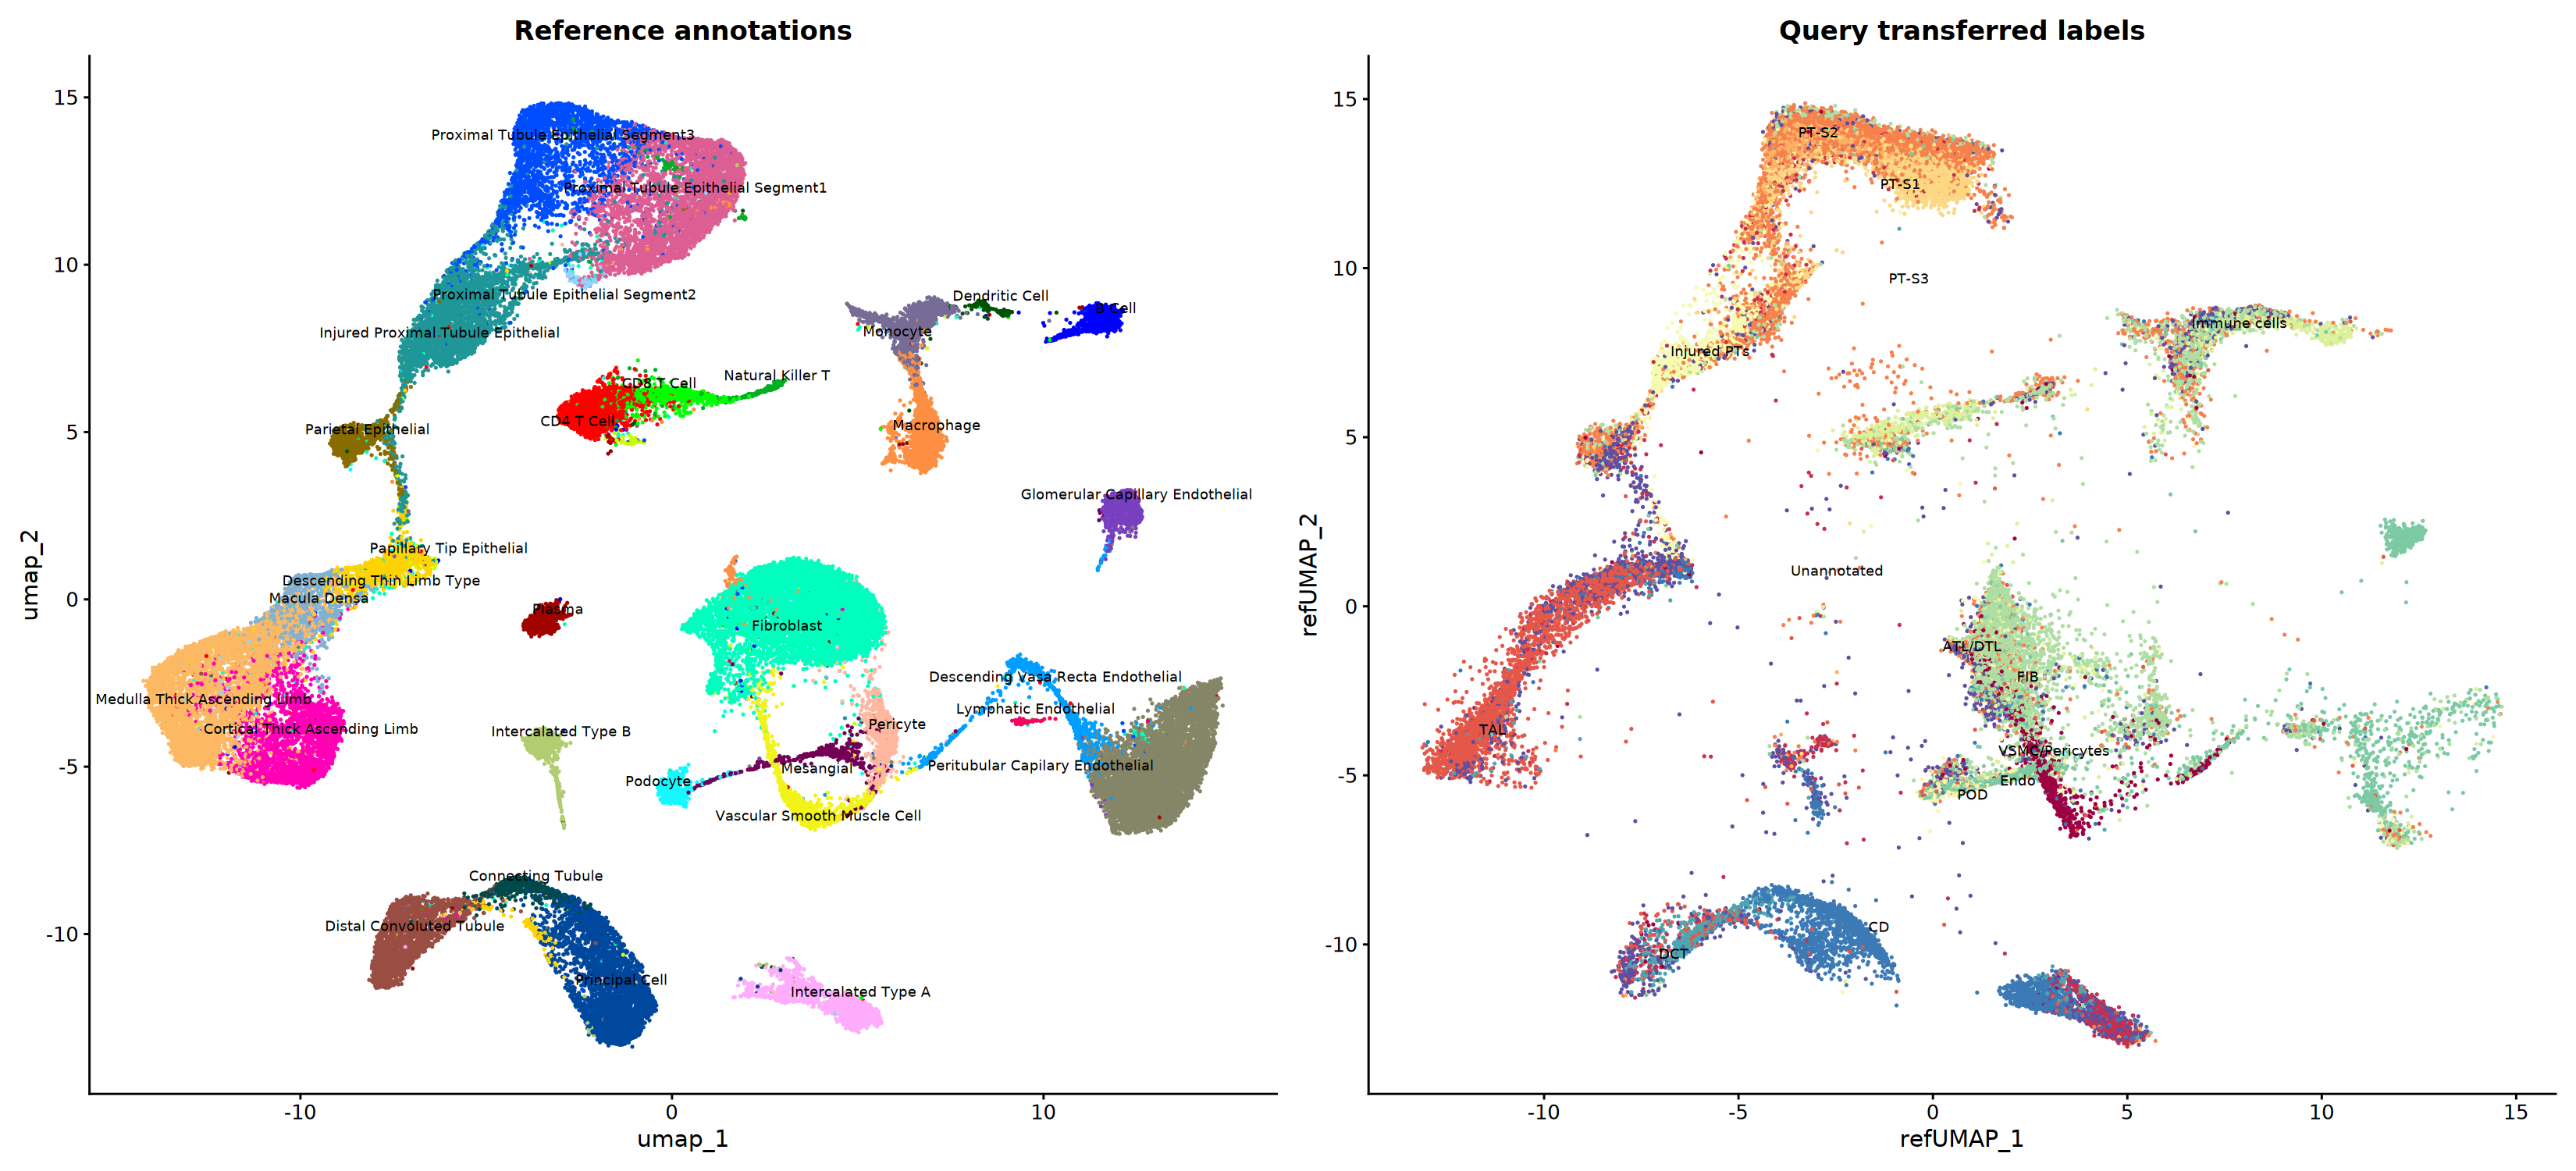

In [34]:
options(repr.plot.width=22, repr.plot.height=10, repr.plot.res = 150)

anno_levels <- levels(factor(muto_data$Annotation))

cols <- Seurat:::DiscretePalette(length(anno_levels))
names(cols) <- anno_levels

cols["Medulla Thick Ascending Limb"] <- "#FDB863"  # 浅橙
cols["Macula Densa"] <- "#80B1D3" 
cols["Connecting Tubule"] <- "#004949"

p1 <- DimPlot(ref, reduction = "umap", group.by = "Annotation", label = TRUE, label.size = 3, repel = TRUE, cols = cols) + NoLegend() + ggtitle("Reference annotations")
p2 <- DimPlot(query, reduction = "ref.umap", group.by = "Clusters2", label = TRUE, label.size = 3, repel = TRUE, cols = SpatialColors(n=length(unique(query@meta.data$Clusters2)))) + NoLegend() + ggtitle("Query transferred labels")
p1 + p2

In [35]:
png("/hpcwork/p0020567/data/dbit-seq/spatial_atac/archr/combined_4_1000/scrna_phase_clustering_reference_mapping_UMAP1.png", width = 6, height = 6, units = "in", res = 600)

p5 <- DimPlot(
  ref,
  reduction = "umap",
  group.by = "Annotation",
  label = FALSE,
  cols = cols
) +
  theme_void() +
  theme(
    legend.position = "none",          # 去 legend
    plot.title = element_blank()       # ⭐ 去 title（关键）
  )

print(p5)
dev.off()

agg_record_57909111 
                  2

In [36]:
pdf("/hpcwork/p0020567/data/dbit-seq/spatial_atac/archr/combined_4_1000/scrna_phase_clustering_reference_mapping_UMAP1.pdf", width = 8, height = 6)
print(p1)
dev.off()

agg_record_710580653 
                   2

In [37]:
ref_umap <- Embeddings(ref, "umap")
query_umap <- Embeddings(query, "ref.umap")

In [38]:
# Combine the UMAP coordinates into a single data frame for plotting
ref_umap_df <- as.data.frame(ref_umap)
ref_umap_df$group <- "Reference"
ref_umap_df$Region <- ref$Annotation

In [39]:
query_umap_df <- as.data.frame(query_umap)
query_umap_df$group <- "Query"
query_umap_df$Region <- query$Clusters2

In [40]:
# Combine the data frames
colnames(query_umap_df) <- c( 'umap_1', 'umap_2', 'group', 'Region')

In [41]:
head(ref_umap_df)

,umap_1,umap_2,group,Region
,<dbl>,<dbl>,<chr>,<chr>
hk_63079_AAACAAGCAATGAGCCACTTTAGG-1,11.498620,-3.9160338,Reference,Descending Vasa Recta Endothelial
hk_63079_AAACAAGCACCAGCTCACTTTAGG-1,5.444658,-0.2796062,Reference,Fibroblast
hk_63079_AAACAAGCACGAACGTACTTTAGG-1,1.080587,12.1533029,Reference,Proximal Tubule Epithelial Segment1
hk_63079_AAACAAGCATTCATGCACTTTAGG-1,2.449909,-1.3930979,Reference,Fibroblast
hk_63079_AAACCAATCAGGGCACACTTTAGG-1,5.214204,-1.1470989,Reference,Fibroblast
hk_63079_AAACCAATCATAATGGACTTTAGG-1,2.358581,0.1526278,Reference,Fibroblast


In [42]:
head(query_umap_df)

,umap_1,umap_2,group,Region
,<dbl>,<dbl>,<chr>,<chr>
63079#GACAGTGCACCACTGT-1,3.963353,-11.52787,Query,Unannotated
63079#GAGTTAGCACATTGGC-1,3.385268,-11.55796,Query,Unannotated
63079#GAACAGGCACAAGCTA-1,2.751997,-11.17975,Query,CD
63079#GACAGTGCACAAGCTA-1,3.600057,-11.11131,Query,CD
63079#CCTCTATCAAGACGGA-1,3.234213,-11.18812,Query,Unannotated
63079#GATGAATCCAGATCTG-1,4.383929,-12.06521,Query,VSMC/Pericytes


In [43]:
query_umap_df1 <- query_umap_df[, c('umap_1', 'umap_2', 'group')]

In [44]:
query_umap_df1$Region <- "spatac"

In [45]:
umap_combined_df <- rbind(ref_umap_df, query_umap_df1)

In [46]:
head(umap_combined_df)

,umap_1,umap_2,group,Region
,<dbl>,<dbl>,<chr>,<chr>
hk_63079_AAACAAGCAATGAGCCACTTTAGG-1,11.498620,-3.9160338,Reference,Descending Vasa Recta Endothelial
hk_63079_AAACAAGCACCAGCTCACTTTAGG-1,5.444658,-0.2796062,Reference,Fibroblast
hk_63079_AAACAAGCACGAACGTACTTTAGG-1,1.080587,12.1533029,Reference,Proximal Tubule Epithelial Segment1
hk_63079_AAACAAGCATTCATGCACTTTAGG-1,2.449909,-1.3930979,Reference,Fibroblast
hk_63079_AAACCAATCAGGGCACACTTTAGG-1,5.214204,-1.1470989,Reference,Fibroblast
hk_63079_AAACCAATCATAATGGACTTTAGG-1,2.358581,0.1526278,Reference,Fibroblast


In [47]:
length(unique(umap_combined_df$Region))

[1] 33

In [48]:
# Plot using ggplot2 to overlay UMAPs
library(ggplot2)


p <- ggplot() +
  # Plot the reference data first (background) with color by region
  geom_point(data = subset(umap_combined_df, group == "Reference"),
             aes(x = umap_1, y = umap_2, color = Region),
             size = 0.8) +
  # Plot the query data on top with black color
  geom_point(data = subset(umap_combined_df, group == "Query"),
             aes(x = umap_1, y = umap_2),
             color = "black",
             size = 0.1) +
  theme_minimal() + theme_void() +
  scale_color_manual(values = SpatialColors(n=length(unique(umap_combined_df$Region)))) +
  ggtitle("Overlay of reference scRNA-seq data and spatial ATAC-seq data UMAPs") +
  theme(legend.position = "right",
        panel.grid.major = element_blank(),  # Remove major gridlines
        panel.grid.minor = element_blank(),  # Remove minor gridlines
        panel.background = element_blank()) +   # Remove panel background
        guides(colour = guide_legend(override.aes = list(size=5)))

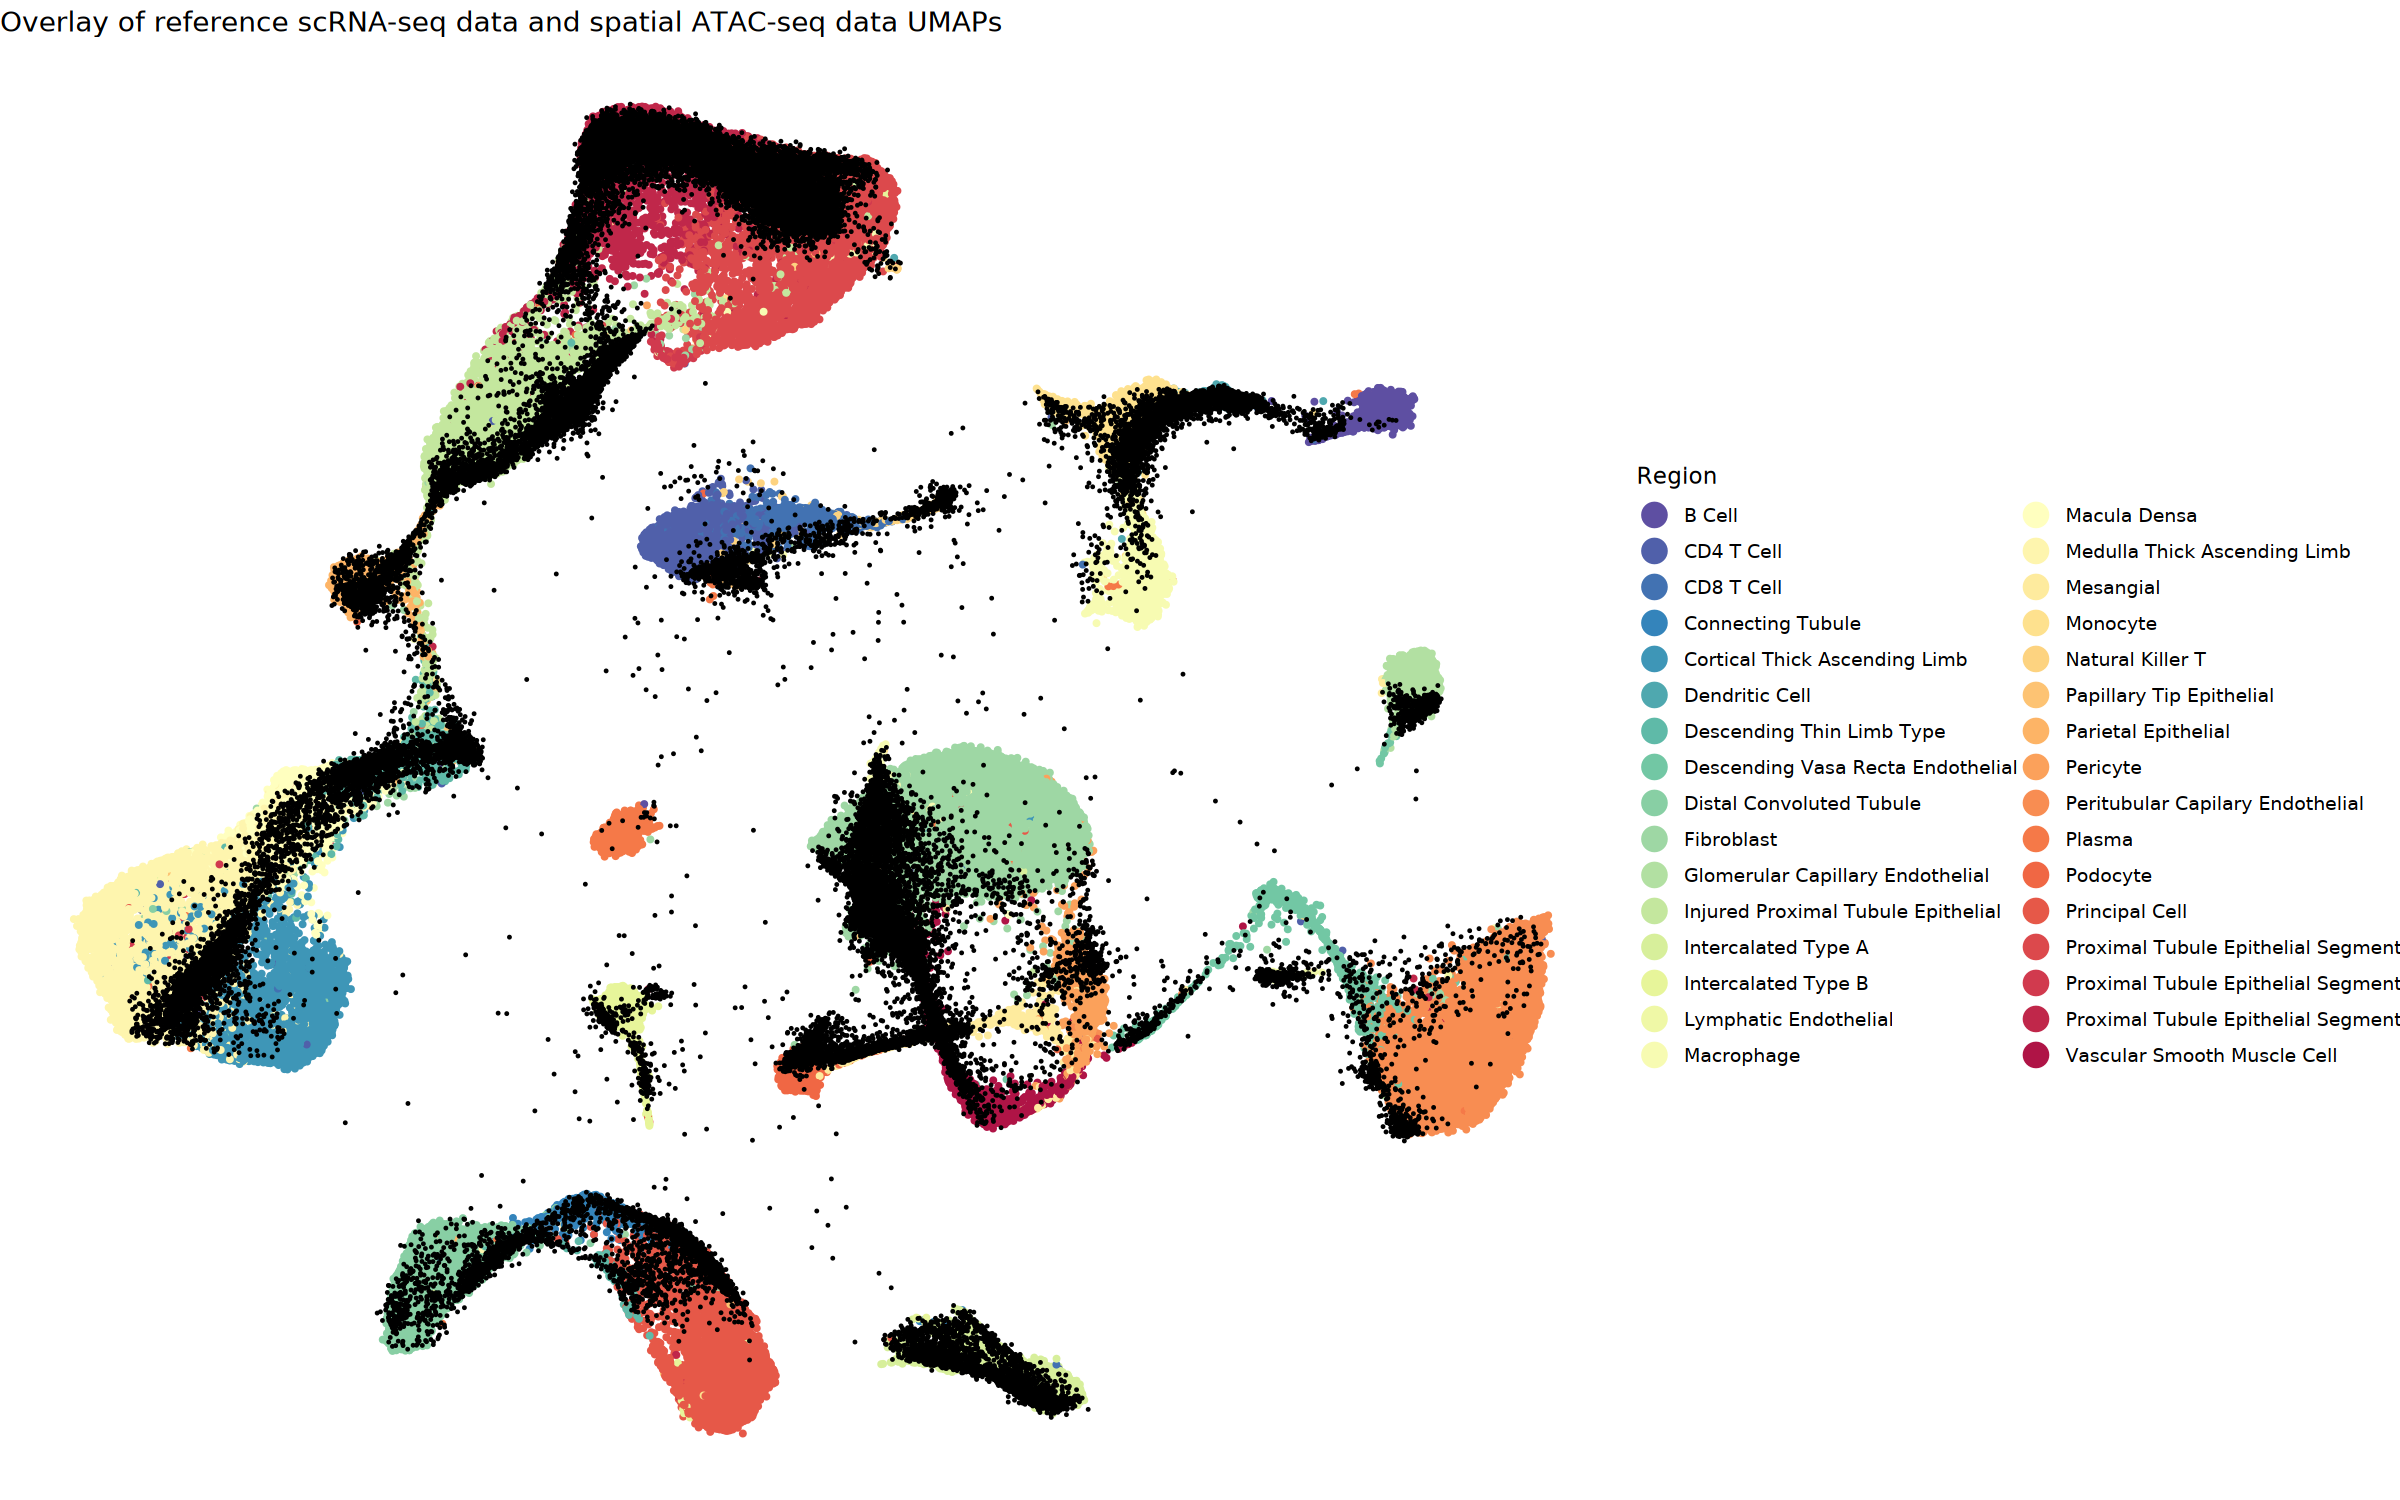

In [49]:
options(repr.plot.width=16, repr.plot.height=10, repr.plot.res = 150)
p

In [50]:
p_projection <- ggplot() +
  # Plot the reference data first (background) with color by region
  geom_point(data = subset(umap_combined_df, group == "Reference"),
             aes(x = umap_1, y = umap_2, color = Region),
             size = 0.8) +
  # Plot the query data on top with black color
  geom_point(data = subset(umap_combined_df, group == "Query"),
             aes(x = umap_1, y = umap_2),
             color = "black",
             size = 0.1) +
  theme_minimal() + theme_void() +
  scale_color_manual(values = cols) +
  ggtitle("Overlay of reference scRNA-seq data and spatial ATAC-seq data UMAPs") +
  theme(legend.position = "right",
        panel.grid.major = element_blank(),  # Remove major gridlines
        panel.grid.minor = element_blank(),  # Remove minor gridlines
        panel.background = element_blank()) +   # Remove panel background
        guides(colour = guide_legend(override.aes = list(size=5)))

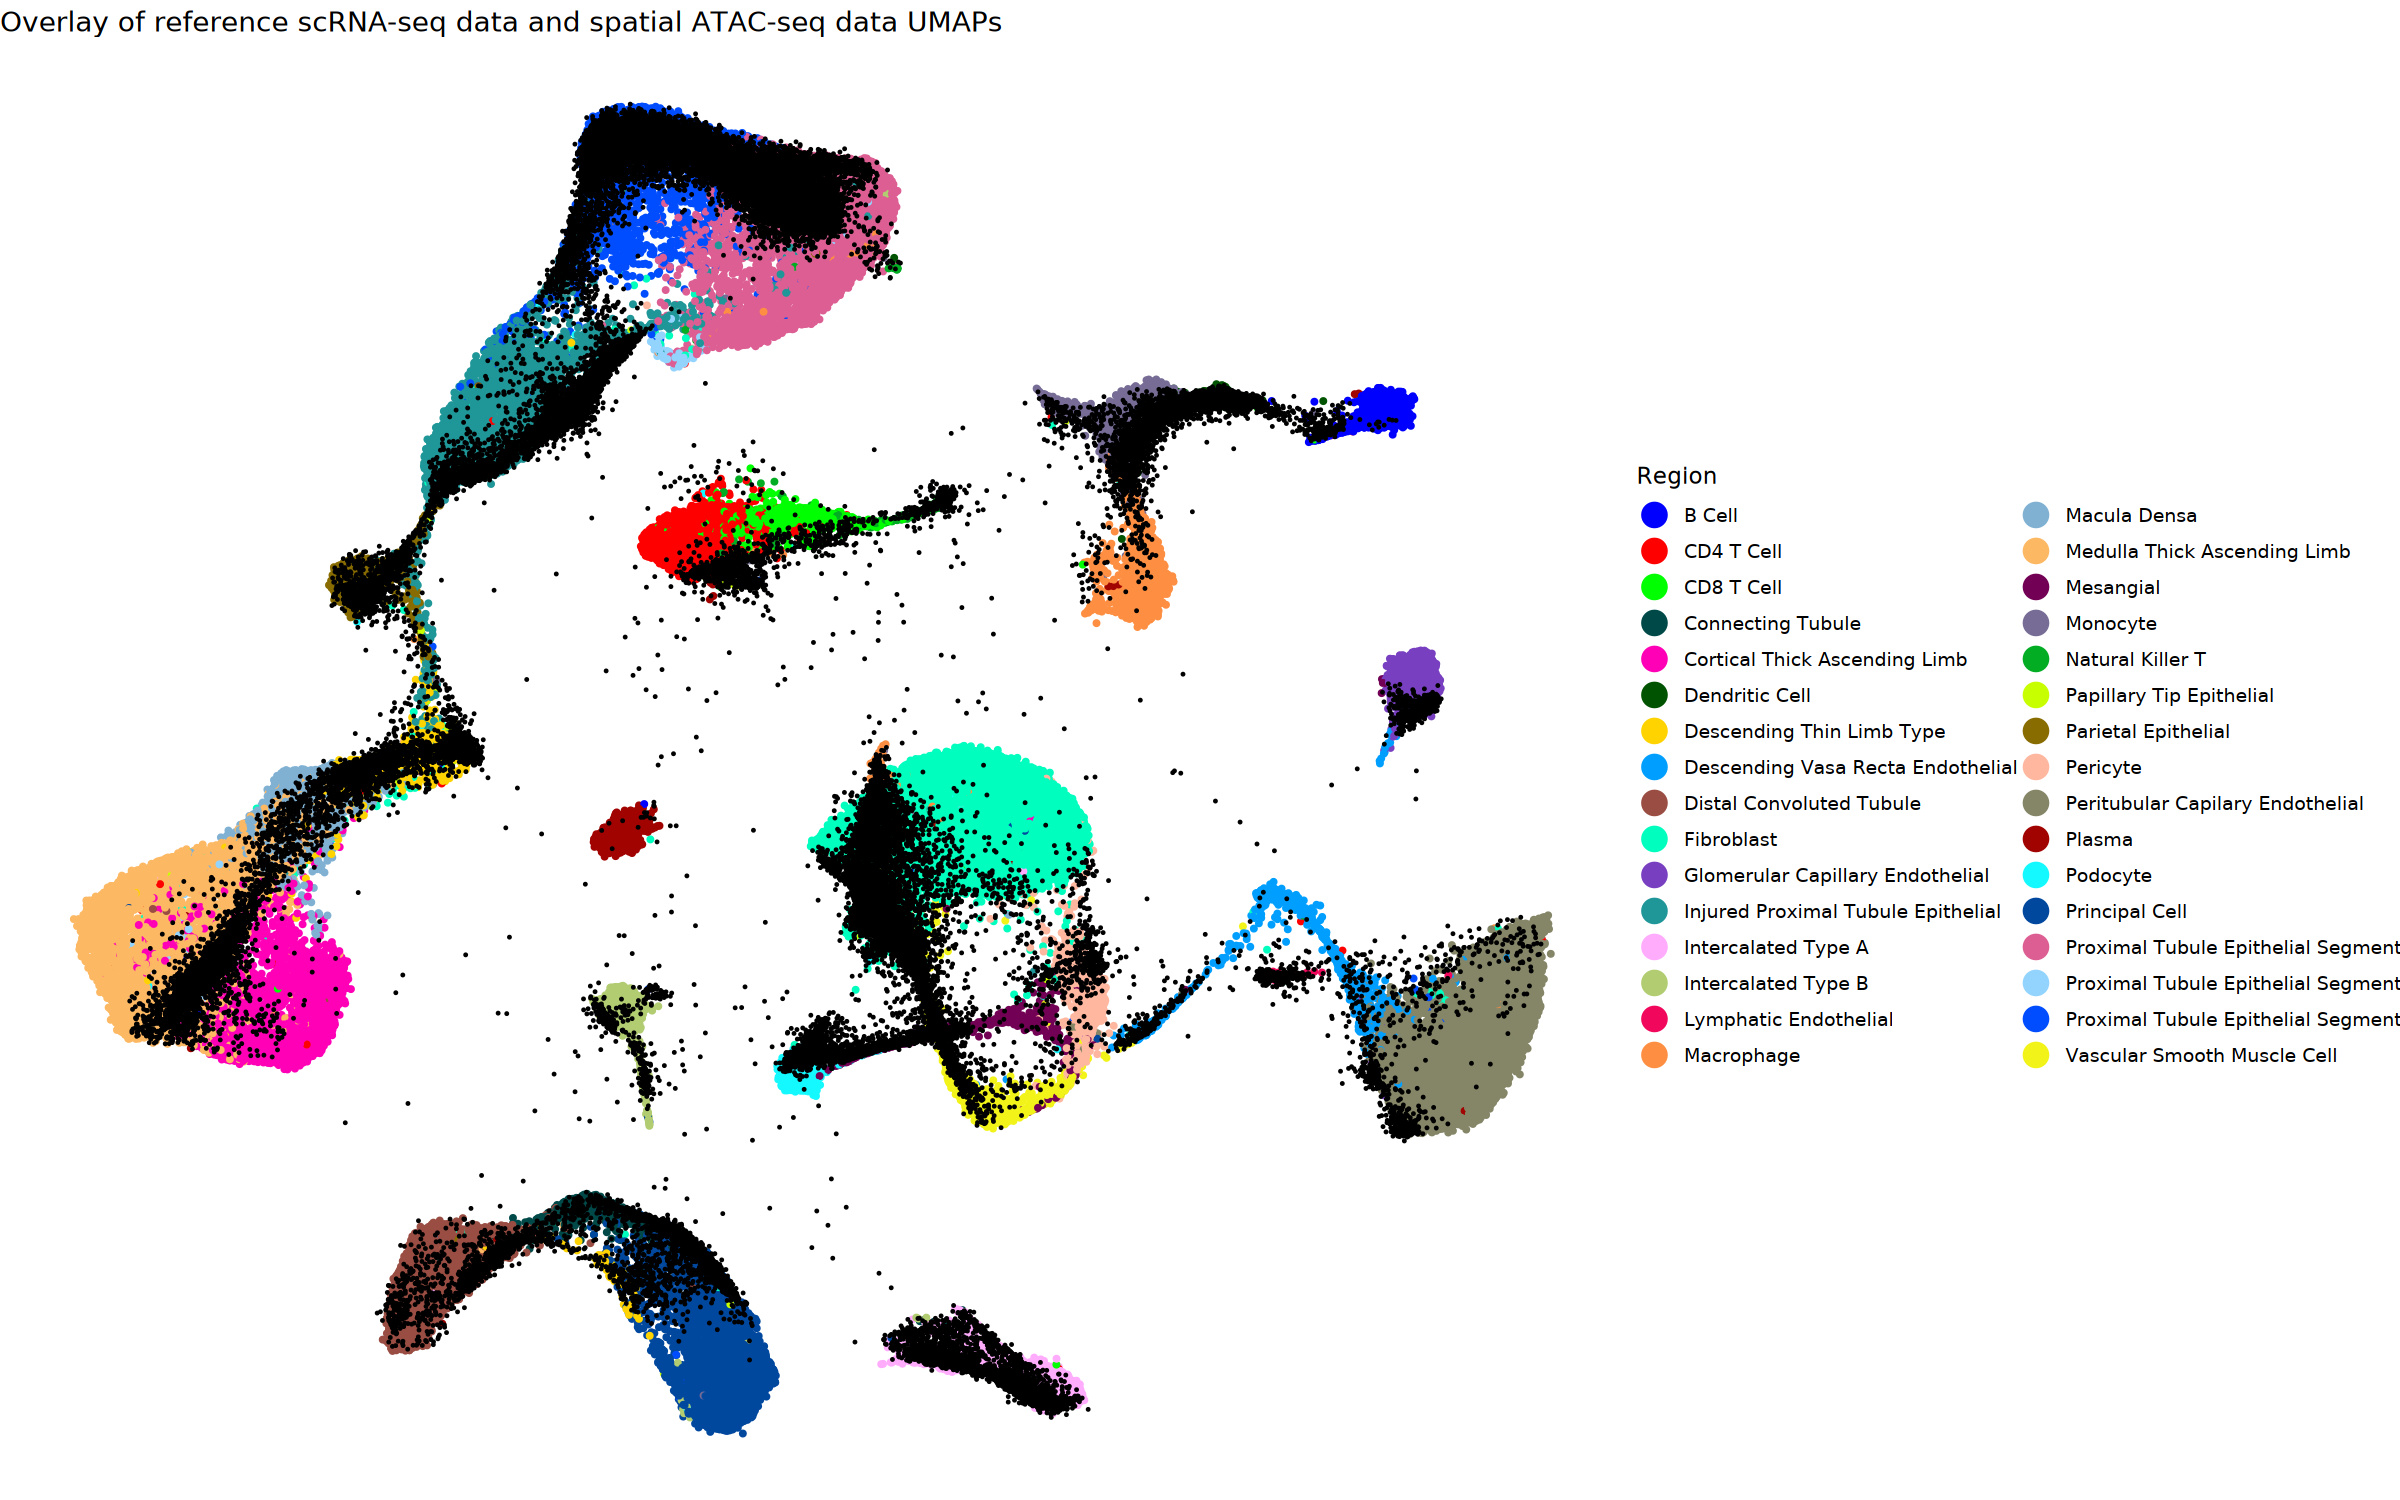

In [51]:
options(repr.plot.width=16, repr.plot.height=10, repr.plot.res = 150)
p_projection

In [52]:
pdf("/hpcwork/p0020567/data/dbit-seq/spatial_atac/archr/combined_4_1000/scrna_phase_clustering_reference_mapping_UMAP2.pdf", width = 16, height = 10)
print(p_projection)
dev.off()

agg_record_1356290666 
                    2

In [72]:
p_projection_png <- ggplot() +
  geom_point(
    data = subset(umap_combined_df, group == "Reference"),
    aes(x = umap_1, y = umap_2, color = Region),
    size = 0.8
  ) +
  geom_point(
    data = subset(umap_combined_df, group == "Query"),
    aes(x = umap_1, y = umap_2),
    color = "#333333",
    size = 0.1,
    #alpha = 0.4
  ) +
  scale_color_manual(values = cols) +
  theme_void() +   # ✅ 去掉所有坐标轴、背景、文字
  theme(
    legend.position = "none"  # ✅ 去掉 legend
  )

In [73]:
ggsave(
  filename = "/hpcwork/p0020567/data/dbit-seq/spatial_atac/archr/combined_4_1000/scrna_phase_clustering_reference_mapping_UMAP2.png",
  plot = p_projection_png,
  width = 10,
  height = 10,
  dpi = 600
)

In [53]:
head(ref_umap_df)

,umap_1,umap_2,group,Region
,<dbl>,<dbl>,<chr>,<chr>
hk_63079_AAACAAGCAATGAGCCACTTTAGG-1,11.498620,-3.9160338,Reference,Descending Vasa Recta Endothelial
hk_63079_AAACAAGCACCAGCTCACTTTAGG-1,5.444658,-0.2796062,Reference,Fibroblast
hk_63079_AAACAAGCACGAACGTACTTTAGG-1,1.080587,12.1533029,Reference,Proximal Tubule Epithelial Segment1
hk_63079_AAACAAGCATTCATGCACTTTAGG-1,2.449909,-1.3930979,Reference,Fibroblast
hk_63079_AAACCAATCAGGGCACACTTTAGG-1,5.214204,-1.1470989,Reference,Fibroblast
hk_63079_AAACCAATCATAATGGACTTTAGG-1,2.358581,0.1526278,Reference,Fibroblast


In [54]:
ref_umap_df1 <- ref_umap_df

In [55]:
ref_umap_df1$Region <- 'scRNA'

In [56]:
umap_combined_df1 <- rbind(ref_umap_df1, query_umap_df)

In [57]:
head(umap_combined_df1)

,umap_1,umap_2,group,Region
,<dbl>,<dbl>,<chr>,<chr>
hk_63079_AAACAAGCAATGAGCCACTTTAGG-1,11.498620,-3.9160338,Reference,scRNA
hk_63079_AAACAAGCACCAGCTCACTTTAGG-1,5.444658,-0.2796062,Reference,scRNA
hk_63079_AAACAAGCACGAACGTACTTTAGG-1,1.080587,12.1533029,Reference,scRNA
hk_63079_AAACAAGCATTCATGCACTTTAGG-1,2.449909,-1.3930979,Reference,scRNA
hk_63079_AAACCAATCAGGGCACACTTTAGG-1,5.214204,-1.1470989,Reference,scRNA
hk_63079_AAACCAATCATAATGGACTTTAGG-1,2.358581,0.1526278,Reference,scRNA


In [61]:
class(cols)

[1] "character"

In [58]:
cols

B Cell                          CD4 T Cell 
                          "#0000FF"                           "#FF0000" 
                         CD8 T Cell                   Connecting Tubule 
                          "#00FF00"                           "#004949" 
      Cortical Thick Ascending Limb                      Dendritic Cell 
                          "#FF00B6"                           "#005300" 
          Descending Thin Limb Type   Descending Vasa Recta Endothelial 
                          "#FFD300"                           "#009FFF" 
           Distal Convoluted Tubule                          Fibroblast 
                          "#9A4D42"                           "#00FFBE" 
   Glomerular Capillary Endothelial  Injured Proximal Tubule Epithelial 
                          "#783FC1"                           "#1F9698" 
                Intercalated Type A                 Intercalated Type B 
                          "#FFACFD"                           "#B1CC71" 
              Lymphatic Endothelial                          Macrophage 
                          "#F1085C"                           "#FE8F42" 
                       Macula Densa        Medulla Thick Ascending Limb 
                          "#80B1D3"                           "#FDB863" 
                          Mesangial                            Monocyte 
                          "#720055"                           "#766C95" 
                   Natural Killer T            Papillary Tip Epithelial 
                          "#02AD24"                           "#C8FF00" 
                Parietal Epithelial                            Pericyte 
                          "#886C00"                           "#FFB79F" 
   Peritubular Capilary Endothelial                              Plasma 
                          "#858567"                           "#A10300" 
                           Podocyte                      Principal Cell 
                          "#14F9FF"                           "#00479E" 
Proximal Tubule Epithelial Segment1 Proximal Tubule Epithelial Segment2 
                          "#DC5E93"                           "#93D4FF" 
Proximal Tubule Epithelial Segment3         Vascular Smooth Muscle Cell 
                          "#004CFF"                           "#F2F318"

In [59]:
# Query数据中的所有Region
region_levels <- sort(unique(
    as.character(
        subset(umap_combined_df1, group == "Query")$Region
    )
))

In [60]:
region_levels

[1] "ATL/DTL"        "CD"             "DCT"            "Endo"          
 [5] "FIB"            "Immune cells"   "Injured PTs"    "POD"           
 [9] "PT-S1"          "PT-S2"          "PT-S3"          "TAL"           
[13] "Unannotated"    "VSMC/Pericytes"

In [62]:
cols1 <- c(
  "ATL/DTL"         = "#FFD300",  # Descending Thin Limb Type

  "CD"              = "#00479E",  # Principal Cell

  "DCT"             = "#9A4D42",  # Distal Convoluted Tubule

  "Endo"            = "#858567",  # Peritubular Capillary Endothelial

  "FIB"             = "#00FFBE",  # Fibroblast

  "Immune cells"    = "#FE8F42",  # Macrophage

  "Injured PTs"     = "#1F9698",  # Injured PT

  "POD"             = "#14F9FF",  # Podocyte

  "PT-S1"           = "#DC5E93",  # PT-S1

  "PT-S2"           = "#93D4FF",  # PT-S2

  "PT-S3"           = "#004CFF",  # PT-S3

  "TAL"             = "#FF00B6",  # Cortical TAL

  "Unannotated"     = "grey70",

  "VSMC/Pericytes"  = "#FFB79F"   # Pericyte
)

In [74]:
p_projection1 <- ggplot() +
  geom_point(
    data = subset(umap_combined_df1, group == "Reference"),
    aes(x = umap_1, y = umap_2),
    color = "grey80",
    size = 0.8
  ) +
  geom_point(
    data = subset(umap_combined_df1, group == "Query"),
    aes(x = umap_1, y = umap_2, color = Region),
    size = 0.1
  ) +
  scale_color_manual(values = cols1) +
  theme_void() +
  ggtitle("Overlay of reference scRNA-seq data and spatial ATAC-seq data UMAPs") +
  theme(
    legend.position = "right",
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank()
  ) +
  guides(colour = guide_legend(override.aes = list(size = 5)))

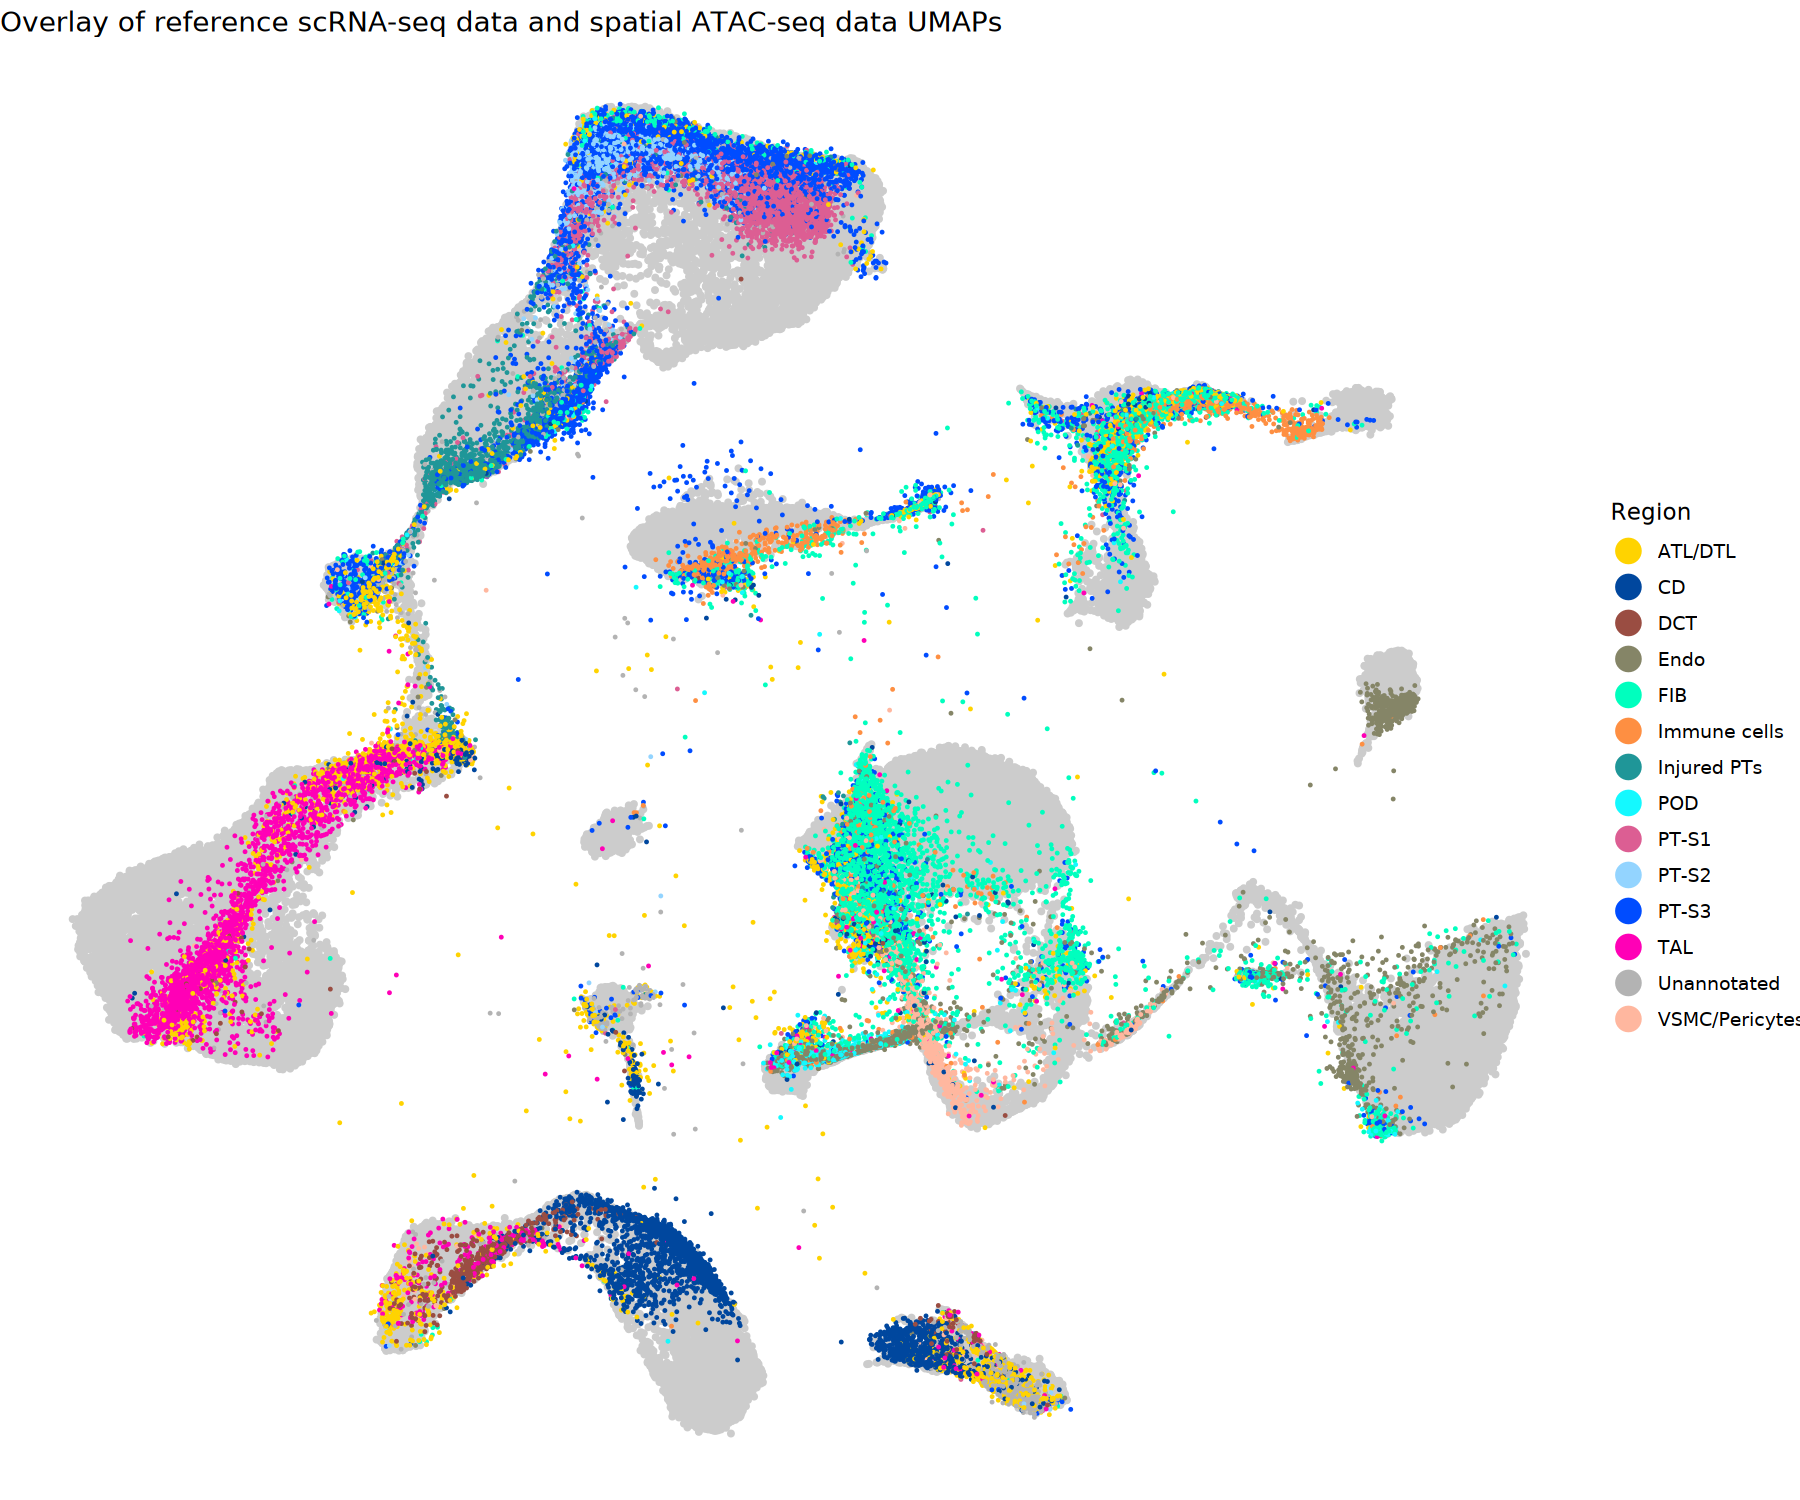

In [75]:
options(repr.plot.width=12, repr.plot.height=10, repr.plot.res = 150)
p_projection1

In [76]:
pdf("/hpcwork/p0020567/data/dbit-seq/spatial_atac/archr/combined_4_1000/scrna_phase_clustering_reference_mapping_UMAP3.pdf", width = 16, height = 10)
print(p_projection1)
dev.off()

agg_record_1089267167 
                    2

In [77]:
p_projection1_png <- ggplot() +
  geom_point(
    data = subset(umap_combined_df1, group == "Reference"),
    aes(x = umap_1, y = umap_2),
    color = "grey80",
    size = 0.8
  ) +
  geom_point(
    data = subset(umap_combined_df1, group == "Query"),
    aes(x = umap_1, y = umap_2, color = Region),
    size = 0.1
  ) +
  scale_color_manual(values = cols1) +
  theme_void() +   # ✅ 去掉所有坐标轴、背景、文字
  theme(
    legend.position = "none"  # ✅ 去掉 legend
  )

In [78]:
ggsave(
  filename = "/hpcwork/p0020567/data/dbit-seq/spatial_atac/archr/combined_4_1000/scrna_phase_clustering_reference_mapping_UMAP3.png",
  plot = p_projection1_png,
  width = 10,
  height = 10,
  dpi = 600
)